In [1]:
### 08/08/2025
### XIAO Han Shawn
### Purpose:
### *** 1. 
###     2. 
###     3. 
### Notes:

## 1. Load data
#-------------------------------------------------------------------------------
wkdir <- "/home/han_xiao/xiaohan/Others/Sunny/02.script/04-Spatial_GUS/s03.SpatialDistribution_GUS.ipynb"
indir <- "/home/han_xiao/xiaohan/Others/Sunny/03.result/04-Spatial_GUS/03.DNA_bwaAdj/"
outdir <- "/home/han_xiao/xiaohan/Others/Sunny/03.result/04-Spatial_GUS/04.FinalProof/"

# if(!dir.exists(wkdir)){dir.create(wkdir,recursive = T)}
if(!dir.exists(indir)){dir.create(indir,recursive = T)}
if(!dir.exists(outdir)){dir.create(outdir,recursive = T)}

source("/home/han_xiao/xiaohan/Work/02-SpatialGF/02.script/ToppingUp/Basic_Config.R")
source("/home/han_xiao/xiaohan/Work/02-SpatialGF/02.script/ToppingUp/Readin_Data.R")

Normalizing layer: counts

Normalizing layer: counts

Normalizing layer: counts

Normalizing layer: counts

Normalizing layer: counts

Normalizing layer: counts



### Merge bin1 expression matrix into bin10

In [2]:
mapq <- 15

In [3]:
df <- read.csv(paste0("/home/han_xiao/xiaohan/Others/Sunny/03.result/04-Spatial_GUS/03.DNA_bwaAdj/Spatial_GUS_MAPQ",mapq,".csv"))
df <- df %>%
  rename_with(
    ~ str_remove(., "_(1_)?(miniLoop|Loop|FMN|hybrid).*$"), 
    cols = -c(CellID, Cx, Cy) 
  )

colnames(df)

[1] "CellID"            "Cx"                "Cy"               
 [4] "B_fragilis"        "B_massiliensis"    "C_perfrigens"     
 [7] "E_Coli"            "E_eligens"         "Eubacterium"      
[10] "F_saccharvivorans" "P_copri"           "R_gnavus"         
[13] "R_hominis"         "S_agalactiae"

In [4]:
# Load required packages
library(tidyverse)
library(ggsci) # Loaded for the NPG color palette used in downstream plotting

# 1. Reshape from wide to long format and clean the data
df_long <- df %>%
  pivot_longer(
    # Important: exclude CellID as well so it is not treated as a gene column
    cols = -c(CellID, Cx, Cy), 
    names_to = "Raw_Column",   
    values_to = "Expression"   
  ) %>%
  # Remove spots with zero expression to eliminate background noise and greatly reduce data size
  filter(Expression > 0)

# 2. Extract GeneName and Category from the column names
df_long <- df_long %>%
  mutate(
    # Match "BT_" followed by consecutive digits as the gene name
    GeneName = Raw_Column,
    # Match "Mucus" or "Lumen" at the end of the string
    Category = Raw_Column
  )

# 3. Spatial coordinate Bin10 downsampling and expression aggregation
df_bin10 <- df_long %>%
  mutate(
    # Spatial binning logic: 268 %/% 10 = 26, 26 * 10 = 260
    Cx_Bin10 = (Cx %/% 10) * 10,
    Cy_Bin10 = (Cy %/% 10) * 10
  ) %>%
  # Group by binned coordinates, gene name and category
  group_by(Cx_Bin10, Cy_Bin10, GeneName, Category) %>%
  # Sum the UMI counts of the same gene within the same bin
  summarise(
    Expression = sum(Expression),
    .groups = "drop" # Ungroup immediately after summarising to keep the data frame clean
  )

# Inspect the final Bin10 structure
head(df_bin10)

Cx_Bin10,Cy_Bin10,GeneName,Category,Expression
<dbl>,<dbl>,<chr>,<chr>,<dbl>
210,17010,B_fragilis,B_fragilis,1
250,16990,B_fragilis,B_fragilis,3
280,3670,B_massiliensis,B_massiliensis,1
460,9620,B_massiliensis,B_massiliensis,1
880,12320,E_eligens,E_eligens,1
990,18360,B_fragilis,B_fragilis,1


正在处理: FMT_P ...

  FMT_P 的 GUS 最大空间表达量为: 4

Plotting metadata column: GUS_Total_UMI

正在处理: FMT_M ...

  FMT_M 的 GUS 最大空间表达量为: 4

Plotting metadata column: GUS_Total_UMI

正在处理: FMT_D ...

  FMT_D 的 GUS 最大空间表达量为: 4

Plotting metadata column: GUS_Total_UMI

批量处理完毕！



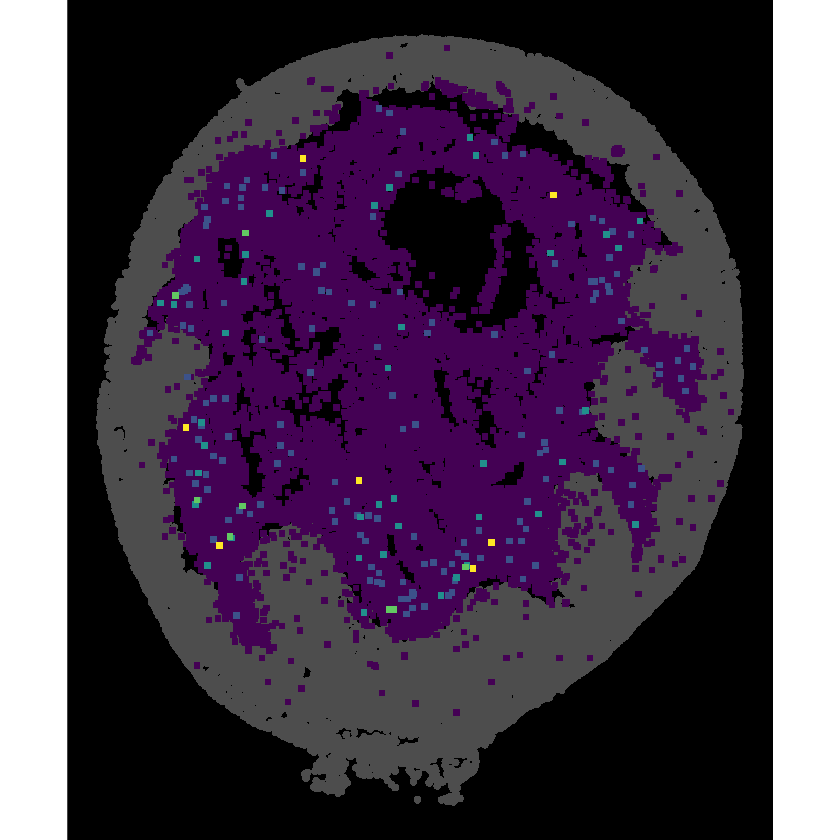

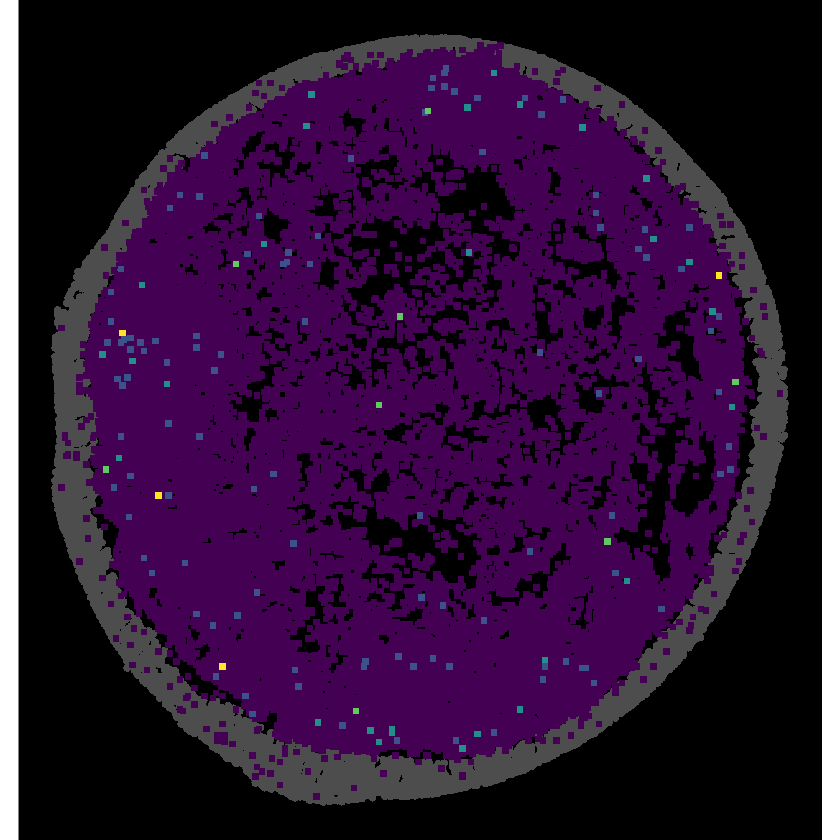

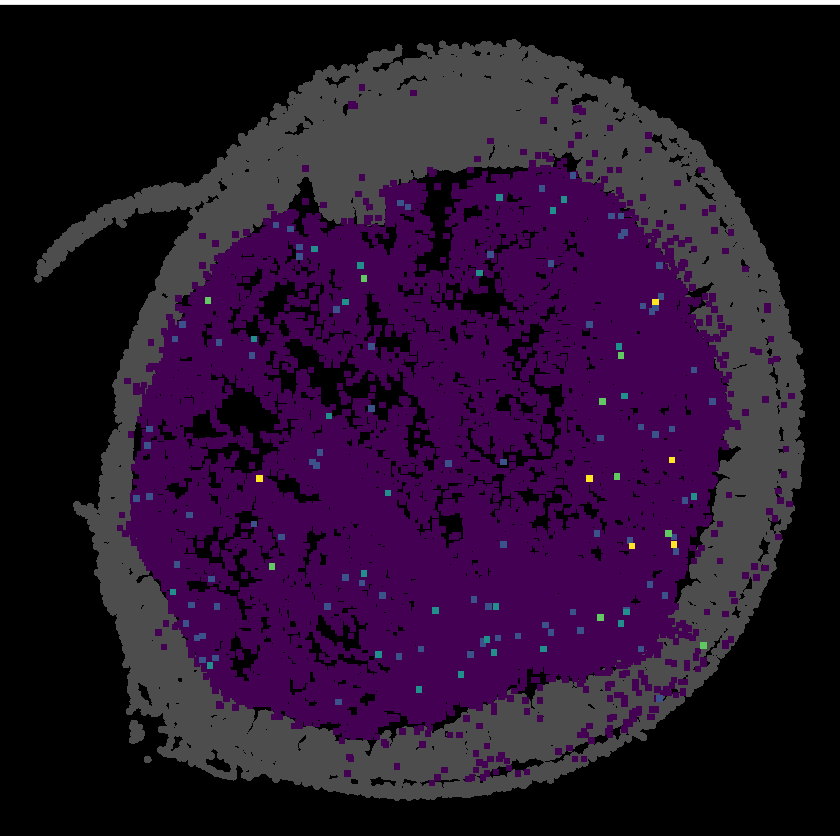

In [5]:
# Load required packages
library(tidyverse)
library(patchwork) # For assembling multi-panel figures

# -------------------------------------------------------------------
# 0. Preparation: sum UMI counts per spatial bin only
# -------------------------------------------------------------------
df_bin10_collapsed <- df_bin10 %>%
  group_by(Cx_Bin10, Cy_Bin10) %>%
  summarise(
    GUS_Total_UMI = sum(Expression), # Sum the expression of all genes in each bin
    .groups = "drop"
  )

# 1. Copy the original list to protect the original micro.list from modification
micro.list.updated <- micro.list

# 2. Create an empty list to collect the generated ggplot objects (one per segment)
plot.list <- list()

# 3. Loop over each group (e.g., "FMT_P", "FMT_M", "FMT_D")
for (segment in names(micro.list)) {
  
  message("Processing: ", segment, " ...")
  
  # Extract the current microbiome and host Seurat objects
  current_micro <- micro.list.updated[[segment]]
  current_host <- host.list[[segment]]
  
  # ---------- A. Extract and update metadata ----------
  meta_data <- current_micro@meta.data
  
  meta_data_updated <- meta_data %>%
    left_join(
      df_bin10_collapsed,
      by = c("x" = "Cx_Bin10", "y" = "Cy_Bin10")
    ) %>%
    mutate(
      # Replace missing values; background spots with no GUS gene alignment are set to 0
      GUS_Total_UMI = replace_na(GUS_Total_UMI, 0)
    )
  
  # Restore row names and write the updated metadata back to current_micro
  rownames(meta_data_updated) <- rownames(meta_data)
  current_micro@meta.data <- meta_data_updated
  
  # Print the maximum value for the current object as a sanity check
  max_umi <- max(current_micro@meta.data$GUS_Total_UMI)
  message("  Maximum spatial GUS expression in ", segment, ": ", max_umi)
  
  # Save the object with updated metadata back to the new list
  micro.list.updated[[segment]] <- current_micro
  
  # ---------- B. Spatial visualization (continuous expression level) ----------
  p <- SpatialMetaDataPlot_HostMicro(
    host.rds = current_host,
    order = TRUE,                     # TRUE: plot high-expression spots on top so they are not hidden by zero-valued background
    micro.rds = current_micro,
    meta.col = "GUS_Total_UMI",       # Map to the UMI sum column computed above
    
    # Note on color scale:
    # Values are raw UMI counts (non-negative integers), not scores ranging from, e.g., -0.21 to 0.95.
    # The minimum is set to 0; a cap at the 99th percentile is recommended to
    # prevent a few extreme spots from compressing the color scale.
    color.min = 0,
    color.max = 4 
  ) 
  
  # Store the plot in plot.list
  plot.list[[segment]] <- p
}

message("Batch processing completed.")

# -------------------------------------------------------------------
# 4. Assemble the figure (using patchwork)
# -------------------------------------------------------------------
# plot.list$FMT_P
# plot.list$FMT_M
# plot.list$FMT_D

### Violin plots comparing spot-to-host distances between G1 and G2

In [12]:
fmt_res <- readRDS("/home/han_xiao/xiaohan/Work/02-SpatialGF/03.result/24.Reproduction/Figure3/Fig3-0.DiscreteWindow_ES.rds")

# ====================================================================
# Load required R packages
# ====================================================================
library(Seurat)
library(ggplot2)
library(patchwork)
library(scales)

# ====================================================================
# Core function: the target_pcs argument sets the number of principal components to use
# ====================================================================
plot_seurat_reduction <- function(fmt_res, reduction_method = "umap", target_pcs = 15) {
  set.seed(666)
  reduction_method <- tolower(reduction_method)
  if (!reduction_method %in% c("umap", "tsne")) {
    stop("Please choose 'umap' or 'tsne' as the dimensionality reduction method")
  }
  
  samples <- c("FMT_P", "FMT_M", "FMT_D")
  plot_list <- list()
  elbow_list <- list()
  
  for (smp in samples) {
    # 1. Extraction and filtering
    es_mat <- fmt_res[[smp]]$Metrics$Enrichment_Score
    valid_taxa <- apply(es_mat, 2, var) > 0
    es_mat_filtered <- es_mat[, valid_taxa, drop = FALSE]
    
    # 2. Pseudocount and log2 transformation
    pseudo_count <- min(es_mat_filtered[es_mat_filtered > 0]) / 2
    if (is.infinite(pseudo_count) || is.na(pseudo_count)) pseudo_count <- 1e-6
    es_mat_log <- log2(es_mat_filtered + pseudo_count)
    
    # 3. Transpose and create the Seurat object
    seurat_counts <- t(es_mat_filtered) 
    seurat_data   <- t(es_mat_log)      
    n_bins <- ncol(seurat_counts)
    
    if (n_bins < 5) {
      warning(paste(smp, "contains too few bins for dimensionality reduction; skipped."))
      next
    }
    
    suppressWarnings({
      seu <- CreateSeuratObject(counts = seurat_counts, project = smp)
    })
    
    if (packageVersion("Seurat") >= "5.0.0") {
      seu[["RNA"]]$data <- seurat_data
    } else {
      seu <- SetAssayData(seu, slot = "data", new.data = seurat_data)
    }
    
    bins <- colnames(seu)
    seu$Distance <- sapply(strsplit(bins, "-"), function(x) min(as.numeric(x)))
    seu <- ScaleData(seu, features = rownames(seu), verbose = FALSE)
    
    # -------------------------------------------------------------
    # Compute the maximum allowed number of PCs so the request does not exceed the data limit
    # -------------------------------------------------------------
    max_possible_pcs <- min(ncol(seu) - 1, nrow(seu) - 1)
    n_pcs <- min(target_pcs, max_possible_pcs)
    
    if (target_pcs > max_possible_pcs) {
      message(paste0("  -> Note: the maximum number of PCs for ", smp, " is ", max_possible_pcs, " (automatically reduced)."))
    }
    
    seu <- RunPCA(seu, features = rownames(seu), npcs = n_pcs, verbose = FALSE)

    # Dynamically set the number of dimensions shown in the elbow plot
    p_elbow <- ElbowPlot(seu, reduction = "pca", ndims = n_pcs) +
      labs(title = paste0(smp, " (PCs: 1-", n_pcs, ")")) +
      theme_bw() +
      theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 12))
    
    elbow_list[[smp]] <- p_elbow
                        
    # 4. Dimensionality reduction
    if (reduction_method == "umap") {
      my_neighbors <- max(2, min(30, floor(n_bins / 2)))
      seu <- RunUMAP(seu, dims = 1:n_pcs, n.neighbors = my_neighbors, verbose = FALSE)
      
    } else if (reduction_method == "tsne") {
      my_perplexity <- max(2, min(30, floor((n_bins - 1) / 3)))
      seu <- RunTSNE(seu, dims = 1:n_pcs, perplexity = my_perplexity, exact = TRUE, verbose = FALSE)
    }
    
    # 5. Visualization
    p <- FeaturePlot(seu, features = "Distance", reduction = reduction_method, pt.size = 0.001) +
      scale_color_viridis_c(
        option = "rocket", direction = -1, name = "Distance",
        limits = c(0, 1000), oob = scales::squish
      ) +
      labs(x = paste0(toupper(reduction_method), " 1"),
        y = paste0(toupper(reduction_method), " 2")) +
      my_theme
    
    plot_list[[smp]] <- p
  }
  
  if (length(plot_list) > 0) {
    final_reduction_plot <- wrap_plots(plot_list, ncol = 3) + plot_layout(guides = "collect")
    final_elbow_plot <- wrap_plots(elbow_list, ncol = 3)
      
    return(list(ReductionPlot = final_reduction_plot, ElbowPlot = final_elbow_plot,seperate_list = plot_list))
  } else {
    return(NULL)
  }
}

In [13]:
###### Final results
pc <- 10
res <- plot_seurat_reduction(fmt_res, reduction_method = "umap", target_pcs = 10)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


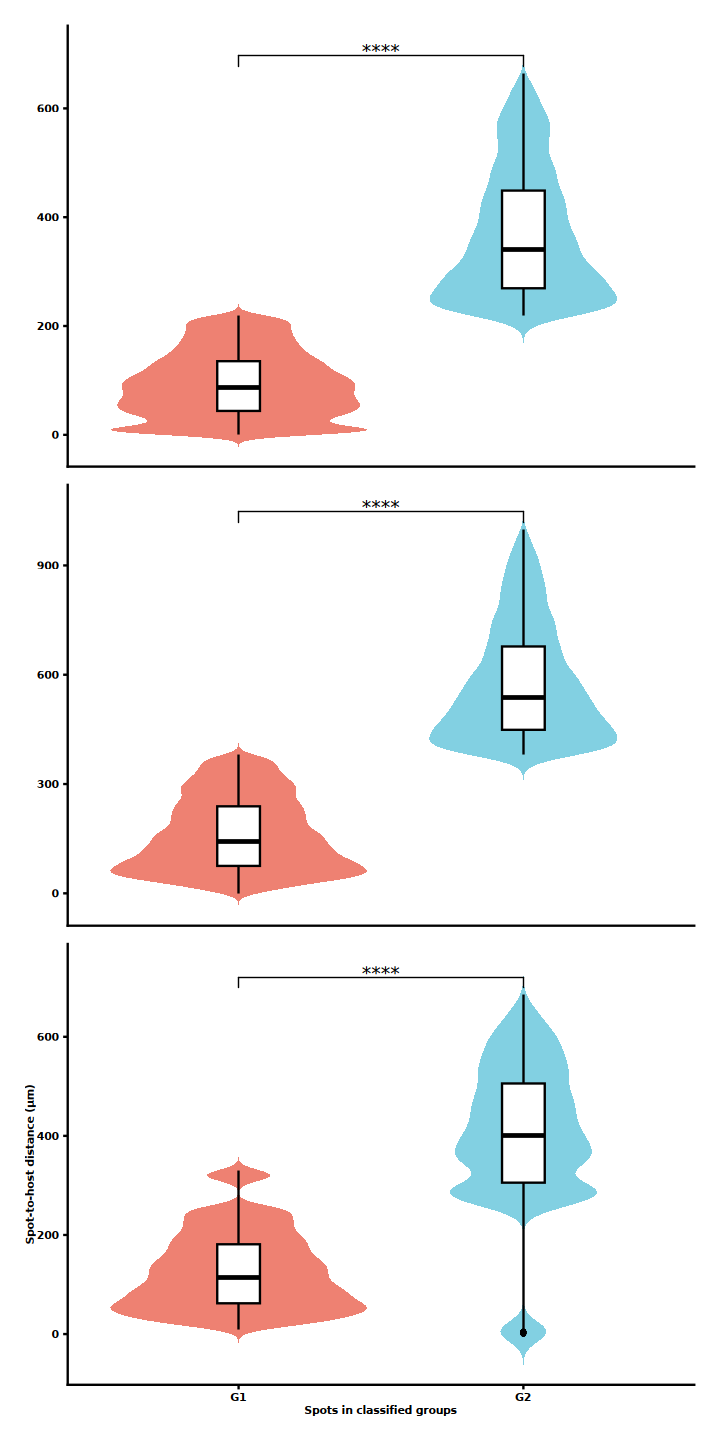

In [14]:
# Load required packages
library(ggplot2)
library(patchwork)
library(ggpubr)

# =========================================================
# 1. Define the core extraction and plotting function
# =========================================================
generate_dist_violin <- function(smp_name, umap_plot_idx, seu_obj) {
  
  # 1. Extract the corresponding UMAP coordinates
  umap_data <- res$ReductionPlot[[umap_plot_idx]]$data
  umap_data$Bin_ID <- rownames(umap_data)
  
  # Identify the UMAP coordinate column names
  umap1_col <- grep("umap_1", colnames(umap_data), ignore.case = TRUE, value = TRUE)[1]
  umap2_col <- grep("umap_2", colnames(umap_data), ignore.case = TRUE, value = TRUE)[1]
  
  # Apply a sample-specific classification rule
  if (smp_name == "FMT_D") {
    target_bins <- c("270-280", "280-290", "300-310")
    line_points <- umap_data[umap_data$Bin_ID %in% target_bins, ]
    
    fit <- lm(as.formula(paste(umap2_col, "~", umap1_col)), data = line_points)
    b <- coef(fit)[1]
    k <- coef(fit)[2]
    
    umap_data$UMAP_Class <- ifelse(umap_data[[umap2_col]] >= (k * umap_data[[umap1_col]] + b), "G2", "G1")
    umap_data$UMAP_Class[umap_data$Bin_ID %in% target_bins] <- "G2" 
    
  } else {
    umap_data$UMAP_Class <- ifelse(umap_data[[umap1_col]] > 5, "G1", "G2")
  }

  # 2. Extract and process the spot-level metadata of the Seurat object
  meta <- seu_obj@meta.data
  meta <- meta[!is.na(meta$min_dist), ]
  
  window_size <- 10
  max_d <- ceiling(max(meta$min_dist, na.rm = TRUE))
  breaks <- seq(0, max_d + window_size, by = window_size) 
  bin_labels <- paste0(breaks[-length(breaks)], "-", breaks[-1])
  
  meta$Bin_ID <- cut(meta$min_dist, breaks = breaks, labels = bin_labels, 
                     include.lowest = TRUE, right = FALSE)
  
  # 3. Map the classification results onto spots
  meta$UMAP_Class <- umap_data$UMAP_Class[match(meta$Bin_ID, umap_data$Bin_ID)]
  plot_meta <- meta[!is.na(meta$UMAP_Class), ]
  
  # 4. Plotting
  plot_meta$UMAP_Class <- factor(plot_meta$UMAP_Class, levels = c("G1", "G2"))
  my_comparisons <- list(c("G1", "G2"))
  
  p <- ggplot(plot_meta, aes(x = UMAP_Class, y = min_dist, fill = UMAP_Class)) +
    geom_violin(trim = FALSE, alpha = 0.7, color = NA) +
    geom_boxplot(width = 0.15, fill = "white", color = "black", 
                 outlier.size = 0.5, outlier.alpha = 0.5) +
    scale_fill_manual(values = c("G1" = "#E64B35", "G2" = "#4DBBD5")) +
    stat_compare_means(
      comparisons = my_comparisons, 
      method = "wilcox.test", 
      label = "p.signif",       
      vjust = 0.5               
    ) +
    # Base label settings
    labs(
      title = NULL, # Ensure no title is generated
      x = NULL,  
      y = "Spot-to-host distance (µm)"
    ) +
    theme_classic() + 
    theme(
      plot.title = element_blank(), # Hide the title layer globally
      axis.text.y = element_text(size = 6, colour = "black", face = "bold"),
      axis.title  = element_text(size = 6, colour = "black", face = "bold"),
      legend.title = element_text(size = 6, colour = "black", face = "bold"),
      legend.text  = element_text(size = 6, colour = "black", face = "bold"),
      panel.grid.major = element_blank(),
      panel.grid.minor = element_blank(),
      strip.text = element_text(size = 6, colour = "black", face = "bold")
    )
  
  # ---------------------------------------------------------
  # Control the display of axis titles and x-axis text by sample
  # ---------------------------------------------------------
  if (smp_name == "FMT_D") {
    # FMT_D is the bottom panel, so keep the G1/G2 labels on the x-axis
    p <- p + 
      theme(
        axis.text.x = element_text(angle = 0, colour = "black", hjust = 0.5, vjust = 1, size = 6, face = "bold")
      )
  } else {
    # FMT_P and FMT_M: hide axis titles, x-axis text and x-axis ticks
    p <- p + 
      theme(
        axis.title.x = element_blank(),    # Hide x-axis title
        axis.title.y = element_blank(),    # Hide y-axis title
        axis.text.x = element_blank(),     # Hide x-axis text (G1, G2)
        axis.ticks.x = element_blank()     # Hide x-axis ticks
      )
  }
  # ---------------------------------------------------------

  return(p)
}

# =========================================================
# 2. Generate the plots for FMT_P, FMT_M and FMT_D
# =========================================================
p_fmt_p <- generate_dist_violin(smp_name = "FMT_P", umap_plot_idx = 1, seu_obj = micro.list$FMT_P)
p_fmt_m <- generate_dist_violin(smp_name = "FMT_M", umap_plot_idx = 2, seu_obj = micro.list$FMT_M)
p_fmt_d <- generate_dist_violin(smp_name = "FMT_D", umap_plot_idx = 3, seu_obj = micro.list$FMT_D)

# =========================================================
# 3. Stack the panels vertically with patchwork and export
# =========================================================
final_plot <- wrap_plots(p_fmt_p, p_fmt_m, p_fmt_d, nrow = 3)

# Add a shared x-axis label at the bottom of the combined figure
final_plot <- final_plot + 
  plot_annotation(theme = theme(plot.margin = margin(10, 10, 10, 10))) & 
  labs(x = "Spots in classified groups")

options(repr.plot.width = 6, repr.plot.height = 12)
print(final_plot & NoLegend())

# Save as PDF
ggsave("Distance_Distribution.DefinedRegion.ViolinPlot.pdf", plot = final_plot & NoLegend(), width = 100/72, height = 180/72, units = "in")

### Bar plot showing the percentage of GUS-expressing spots in the mucus-associated and lumen-associated regions

In [15]:
combined_data <- read.csv("/home/han_xiao/xiaohan/Work/02-SpatialGF/03.result/23.Figures/Fig3/Fig3C.UMAP_Coordinates_All_Integrated.csv")

In [16]:
head(micro.list.updated$FMT_P@meta.data)

,_index,nCount_Spatial,nFeature_Spatial,orig.ident,percent.mito,x,y,condition_segment,percent.ct,Taxon,Count,Sd,min_dist,GUS_Total_UMI
,<chr>,<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
54803782713550,54803782713550,27,16,sample,0,12760,16590,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,5,1.1547005,227.95285,0
52613349391920,52613349391920,11,9,sample,0,12250,15920,FMT_P,0.000000,Others,NA,0.4629100,179.03421,0
53171695139510,53171695139510,15,4,sample,0,12380,15030,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,9,1.4571811,253.07114,0
54760833041020,54760833041020,10,8,sample,0,12750,17020,FMT_P,0.000000,Others,NA,3.4334951,50.32892,0
55276229115040,55276229115040,13,10,sample,0,12870,15520,FMT_P,0.000000,Others,NA,0.4409586,506.51999,0
57337813419170,57337813419170,27,21,sample,0,13350,17570,FMT_P,3.703704,Others,NA,0.7264832,43.18565,0


In [17]:
# Assumes the integrated table generated in the previous step is available in the environment as combined_data.
# If not, read it first:
# combined_data <- read.csv("Fig3C.UMAP_Coordinates_All_Integrated.csv")

# Loop over each Seurat object in micro.list.updated
for (smp in names(micro.list.updated)) {
  
  # 1. Extract the metadata of the current Seurat object
  seu_obj <- micro.list.updated[[smp]]
  meta <- seu_obj@meta.data
  
  # 2. Compute Bin_ID from min_dist (spots with NA are ignored when computing the maximum)
  window_size <- 10
  max_d <- ceiling(max(meta$min_dist, na.rm = TRUE))
  breaks <- seq(0, max_d + window_size, by = window_size) 
  bin_labels <- paste0(breaks[-length(breaks)], "-", breaks[-1])
  
  meta$Bin_ID <- cut(meta$min_dist, breaks = breaks, labels = bin_labels, 
                     include.lowest = TRUE, right = FALSE)
  
  # 3. Extract the UMAP classification data for the current sample from the integrated table
  # Note: the table contains a Sample column, and the group column is named Group
  umap_data <- subset(combined_data, Sample == smp)
  
  # 4. Map the classification onto spots by Bin_ID and store it in the umap_group column
  meta$umap_group <- umap_data$Group[match(meta$Bin_ID, umap_data$Bin_ID)]
  
  # Convert umap_group to a factor to standardize downstream analysis and plotting
  meta$umap_group <- factor(meta$umap_group, levels = c("G1", "G2"))
  
  # 5. Write the updated metadata back to the Seurat object and update micro.list.updated
  seu_obj@meta.data <- meta
  micro.list.updated[[smp]] <- seu_obj
  
  message("Successfully added umap_group to the metadata of ", smp)
}

# Verify that the column was added (using FMT_P as an example)
head(micro.list.updated$FMT_P@meta.data[, c("GUS_Total_UMI","min_dist", "Bin_ID", "umap_group")])

✅ 成功整合 FMT_P 的 umap_group 到 meta.data

✅ 成功整合 FMT_M 的 umap_group 到 meta.data

✅ 成功整合 FMT_D 的 umap_group 到 meta.data



,GUS_Total_UMI,min_dist,Bin_ID,umap_group
,<dbl>,<dbl>,<fct>,<fct>
54803782713550,0,227.95285,220-230,G2
52613349391920,0,179.03421,170-180,G1
53171695139510,0,253.07114,250-260,G2
54760833041020,0,50.32892,50-60,G1
55276229115040,0,506.51999,500-510,G2
57337813419170,0,43.18565,40-50,G1


In [18]:
head(micro.list.updated$FMT_P@meta.data)
head(micro.list.updated$FMT_P@meta.data)
head(micro.list.updated$FMT_P@meta.data)

,_index,nCount_Spatial,nFeature_Spatial,orig.ident,percent.mito,x,y,condition_segment,percent.ct,Taxon,Count,Sd,min_dist,GUS_Total_UMI,Bin_ID,umap_group
,<chr>,<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>
54803782713550,54803782713550,27,16,sample,0,12760,16590,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,5,1.1547005,227.95285,0,220-230,G2
52613349391920,52613349391920,11,9,sample,0,12250,15920,FMT_P,0.000000,Others,NA,0.4629100,179.03421,0,170-180,G1
53171695139510,53171695139510,15,4,sample,0,12380,15030,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,9,1.4571811,253.07114,0,250-260,G2
54760833041020,54760833041020,10,8,sample,0,12750,17020,FMT_P,0.000000,Others,NA,3.4334951,50.32892,0,50-60,G1
55276229115040,55276229115040,13,10,sample,0,12870,15520,FMT_P,0.000000,Others,NA,0.4409586,506.51999,0,500-510,G2
57337813419170,57337813419170,27,21,sample,0,13350,17570,FMT_P,3.703704,Others,NA,0.7264832,43.18565,0,40-50,G1


,_index,nCount_Spatial,nFeature_Spatial,orig.ident,percent.mito,x,y,condition_segment,percent.ct,Taxon,Count,Sd,min_dist,GUS_Total_UMI,Bin_ID,umap_group
,<chr>,<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>
54803782713550,54803782713550,27,16,sample,0,12760,16590,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,5,1.1547005,227.95285,0,220-230,G2
52613349391920,52613349391920,11,9,sample,0,12250,15920,FMT_P,0.000000,Others,NA,0.4629100,179.03421,0,170-180,G1
53171695139510,53171695139510,15,4,sample,0,12380,15030,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,9,1.4571811,253.07114,0,250-260,G2
54760833041020,54760833041020,10,8,sample,0,12750,17020,FMT_P,0.000000,Others,NA,3.4334951,50.32892,0,50-60,G1
55276229115040,55276229115040,13,10,sample,0,12870,15520,FMT_P,0.000000,Others,NA,0.4409586,506.51999,0,500-510,G2
57337813419170,57337813419170,27,21,sample,0,13350,17570,FMT_P,3.703704,Others,NA,0.7264832,43.18565,0,40-50,G1


,_index,nCount_Spatial,nFeature_Spatial,orig.ident,percent.mito,x,y,condition_segment,percent.ct,Taxon,Count,Sd,min_dist,GUS_Total_UMI,Bin_ID,umap_group
,<chr>,<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>
54803782713550,54803782713550,27,16,sample,0,12760,16590,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,5,1.1547005,227.95285,0,220-230,G2
52613349391920,52613349391920,11,9,sample,0,12250,15920,FMT_P,0.000000,Others,NA,0.4629100,179.03421,0,170-180,G1
53171695139510,53171695139510,15,4,sample,0,12380,15030,FMT_P,0.000000,Emergencia-sp.-JLR.KK010,9,1.4571811,253.07114,0,250-260,G2
54760833041020,54760833041020,10,8,sample,0,12750,17020,FMT_P,0.000000,Others,NA,3.4334951,50.32892,0,50-60,G1
55276229115040,55276229115040,13,10,sample,0,12870,15520,FMT_P,0.000000,Others,NA,0.4409586,506.51999,0,500-510,G2
57337813419170,57337813419170,27,21,sample,0,13350,17570,FMT_P,3.703704,Others,NA,0.7264832,43.18565,0,40-50,G1


In [19]:
micro.list.updated$FMT_P@meta.data %>% filter(umap_group=="G1") %>% pull(min_dist) %>% summary()
micro.list.updated$FMT_M@meta.data %>% filter(umap_group=="G1") %>% pull(min_dist) %>% summary()
micro.list.updated$FMT_D@meta.data %>% filter(umap_group=="G1") %>% pull(min_dist) %>% summary()

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00   43.92   86.50   92.08  135.35  220.00 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00   75.27  143.55  160.81  238.81  379.98 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  10.01   62.10  114.22  127.12  181.22  329.99 

In [20]:
head(micro.list.updated$FMT_P@meta.data[, c("GUS_Total_UMI","min_dist", "Bin_ID", "umap_group")])

,GUS_Total_UMI,min_dist,Bin_ID,umap_group
,<dbl>,<dbl>,<fct>,<fct>
54803782713550,0,227.95285,220-230,G2
52613349391920,0,179.03421,170-180,G1
53171695139510,0,253.07114,250-260,G2
54760833041020,0,50.32892,50-60,G1
55276229115040,0,506.51999,500-510,G2
57337813419170,0,43.18565,40-50,G1


In [21]:
micro.list.updated

$FMT_P
An object of class Seurat 
10760 features across 31639 samples within 1 assay 
Active assay: Spatial (10760 features, 0 variable features)
 3 layers present: counts, data, scale.data
 1 image present: slice

$FMT_M
An object of class Seurat 
10760 features across 40136 samples within 1 assay 
Active assay: Spatial (10760 features, 0 variable features)
 3 layers present: counts, data, scale.data
 1 image present: slice

$FMT_D
An object of class Seurat 
10760 features across 28795 samples within 1 assay 
Active assay: Spatial (10760 features, 0 variable features)
 3 layers present: counts, data, scale.data
 1 image present: slice


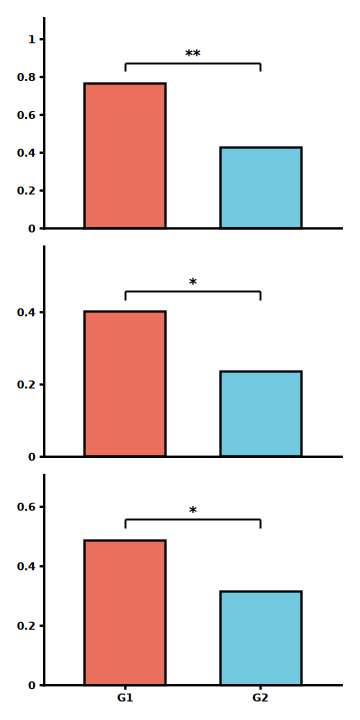

In [22]:
# Load required R packages
library(Seurat)
library(dplyr)
library(ggplot2)
library(scales)
library(patchwork) 

my_theme <- 
  theme_classic() +
  theme(title = element_text(angle = 0, colour = "black", hjust = 0.5, vjust = 1, size = 6, face = "bold"),
        plot.subtitle = element_text(angle = 0, colour = "black", hjust = 0.5, vjust = 1, size = 6, face = "bold"),
        axis.text.x = element_text(angle = 0, colour = "black", size = 6, face = "bold"),
        axis.text.y = element_text(size = 6, colour = "black", face = "bold"),
        axis.title  = element_text(size = 6, colour = "black", face = "bold"),
        legend.title = element_text(size = 6, colour = "black", face = "bold"),
        legend.text  = element_text(size = 6, colour = "black", face = "bold"),
        #panel.border = element_rect(color = "black", linewidth = 1),
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        strip.text = element_text(size = 6, colour = "black", face = "bold")
  )

# Define a function that analyzes a single Seurat object and returns statistics and a plot
analyze_and_plot <- function(seurat_obj, sample_name) {
  
  # 1. Extract the metadata and remove rows containing NA values
  meta <- seurat_obj@meta.data %>%
    filter(!is.na(umap_group), !is.na(GUS_Total_UMI))
  
  # 2. Add a column indicating whether GUS_Total_UMI is greater than 0
  meta <- meta %>%
    mutate(Expressed_Status = ifelse(GUS_Total_UMI > 0, "Expressed", "Not_Expressed"))
  
  # 3. Chi-square test
  cont_table <- table(meta$umap_group, meta$Expressed_Status)
  chi_res <- chisq.test(cont_table)
  p_val <- chi_res$p.value
  
  # Define significance symbols
  sig_label <- case_when(
    p_val < 0.001 ~ "***",
    p_val < 0.01  ~ "**",
    p_val < 0.05  ~ "*",
    TRUE          ~ "ns"
  )
  
  # 4. Calculate the proportion of expressed spots per group
  prop_df <- meta %>%
    group_by(umap_group) %>%
    summarise(
      Total_Spots = n(),
      Expressed_Spots = sum(Expressed_Status == "Expressed"),
      Proportion = Expressed_Spots / Total_Spots,
      .groups = "drop"
    )
  
  # ---- Dynamically compute the y positions of the bracket and asterisks ----
  y_max <- max(prop_df$Proportion)
  # Use a gap relative to the maximum (10%) so that differing data scales across samples do not cause misalignment
  y_gap <- ifelse(y_max == 0, 0.01, y_max * 0.1) 
  
  y_line <- y_max + y_gap * 1.4  # Height of the horizontal line
  y_tip  <- y_max + y_gap * 0.8  # Height of the short vertical ticks at both ends
  y_text <- y_line + y_gap * 0.2 # Height of the asterisk label
  
  # 5. Draw a bar plot with the significance annotation
  p <- ggplot(prop_df, aes(x = umap_group, y = Proportion, fill = umap_group)) +
    geom_bar(stat = "identity", width = 0.6, color = "black", alpha = 0.8) +
    
    # Manually add the significance bracket and asterisks (the discrete x-axis levels "G1" and "G2" correspond to positions 1 and 2)
    annotate("segment", x = 1, xend = 2, y = y_line, yend = y_line, linewidth = 0.4, color = "black") +
    annotate("segment", x = 1, xend = 1, y = y_line, yend = y_tip, linewidth = 0.4, color = "black") +
    annotate("segment", x = 2, xend = 2, y = y_line, yend = y_tip, linewidth = 0.4, color = "black") +
    annotate("text", x = 1.5, y = y_text, label = sig_label, size = 3, fontface = "bold", vjust = 0, color = "black") +
    
    scale_y_continuous(
      labels = function(x) x * 100, 
      breaks = seq(0, 1, by = 0.002), 
      # Extend the upper limit by 25% to leave enough room for the asterisks
      expand = expansion(mult = c(0, 0.25))
    ) +
    labs(
      # title = paste0(sample_name),
      # subtitle = paste0("P = ", signif(p_val, 1)),
      x = NULL,
      y = NULL # "Proportion of expressed spots in groups (%)"
    ) +
    my_theme +
    scale_fill_manual(values = c("G1" = "#E64B35", "G2" = "#4DBBD5")) + NoLegend()
  
  return(list(
    prop_data = prop_df,
    chisq_result = chi_res,
    plot = p
  ))
}

# Apply the function to every sample
results_list <- lapply(names(micro.list.updated), function(sample_name) {
  analyze_and_plot(micro.list.updated[[sample_name]], sample_name)
})
names(results_list) <- names(micro.list.updated)

# --- Extract and display results ---
all_plots <- lapply(results_list, function(x) x$plot)

# ======= Control x-axis display for the vertical layout =======
# Remove the x-axis text and ticks from the first and second plots
all_plots[[1]] <- all_plots[[1]] + theme(axis.text.x = element_blank(), axis.ticks.x = element_blank())
all_plots[[2]] <- all_plots[[2]] + theme(axis.text.x = element_blank(), axis.ticks.x = element_blank())

# Stack the plots vertically (ncol = 1)
final_plot <- wrap_plots(all_plots, ncol = 1)

# Adjust the output size for the vertical layout (narrower width, greater height)
options(repr.plot.width = 3, repr.plot.height = 6)
final_plot

ggsave("Propotion_Expressed_Spot.StatisticalTest.boxplot.pdf", final_plot, width = 70/72, height = 165/72, units = "in")

In [23]:
table(ifelse(micro.list.updated$FMT_P$min_dist<=150,"G1","G2"))
table(ifelse(micro.list.updated$FMT_M$min_dist<=150,"G1","G2"))
table(ifelse(micro.list.updated$FMT_D$min_dist<=150,"G1","G2"))

428606 / 393318
466496 / 829159
418777 / 458309

18492 / 13147
16491 / 23645
12955 / 15840 


   G1    G2 
18492 13147 


   G1    G2 
16491 23645 


   G1    G2 
12955 15840 

[1] 1.089719

[1] 0.5626134

[1] 0.9137438

[1] 1.406557

[1] 0.6974413

[1] 0.8178662

### Pie chart showing the taxonomic composition and relative proportions of GUS-derived deduplicated transcript molecules

In [25]:
main_sub_dir <- "."

In [26]:
# -------------------------------------------------------------------
# 5. Draw and save the donut chart of species proportions
# -------------------------------------------------------------------
message("Calculating species proportions and drawing the donut chart...")

# Calculate the total UMI count and the fraction for each species
species_summary <- df_long %>%
  group_by(GeneName) %>%
  summarise(Total_UMI = sum(Expression), .groups = "drop") %>%
  mutate(
    Fraction = Total_UMI / sum(Total_UMI),
    Percentage = Fraction * 100,
    # Legend label format: species name (percentage%), one decimal place
    Legend_Label = sprintf("%s (%.1f%%)", GeneName, Percentage)
  ) %>%
  # Sort by expression in descending order so the chart and legend are well organized
  arrange(desc(Total_UMI)) 

# Convert labels to a factor to fix the legend order (largest to smallest)
species_summary$Legend_Label <- factor(species_summary$Legend_Label, levels = species_summary$Legend_Label)

# Draw the donut chart
p_donut <- ggplot(species_summary, aes(x = 2, y = Fraction, fill = Legend_Label)) +
  geom_bar(stat = "identity", color = "white", width = 1) +
  # Convert to polar coordinates to draw the pie chart
  coord_polar(theta = "y", start = 0) +
  # Limit the x-axis range to hollow out the center and form a donut (the region from 0.5 to 1.5 is empty)
  xlim(0.5, 2.5) + 
  theme_void() + # Remove axes and grid background
  theme(
    legend.position = "right",
    legend.title = element_blank(), # Hide the legend title
    legend.text = element_text(size = 11),
    plot.title = element_text(hjust = 0.5, face = "bold", size = 14)
  ) +
  labs(title = paste0("Species UMI Proportion (MAPQ = ", mapq, ")")) +
  # If there are many species, use a palette with high discriminability, e.g., Set3 or Paired
  scale_fill_brewer(palette = "Set3") 

# Save the figure (output both PNG and PDF for later layout)
donut_png <- paste0(main_sub_dir, "MAPQ", mapq, "_Species_Proportion_Donut.Proportional.png")
donut_pdf <- paste0(main_sub_dir, "MAPQ", mapq, "_Species_Proportion_Donut.Proportional.pdf")

ggsave(donut_png, p_donut, dpi = 300, width = 8, height = 6)
ggsave(donut_pdf, p_donut, dpi = 300, width = 8, height = 6)

message("Donut chart calculated and saved.")

write.csv(species_summary,paste0(main_sub_dir, "MAPQ", mapq, "_Species_Proportion_Donut.plotdata.csv"))

正在计算 Species 占比并绘制环形饼图...

环形饼图计算与保存完毕！



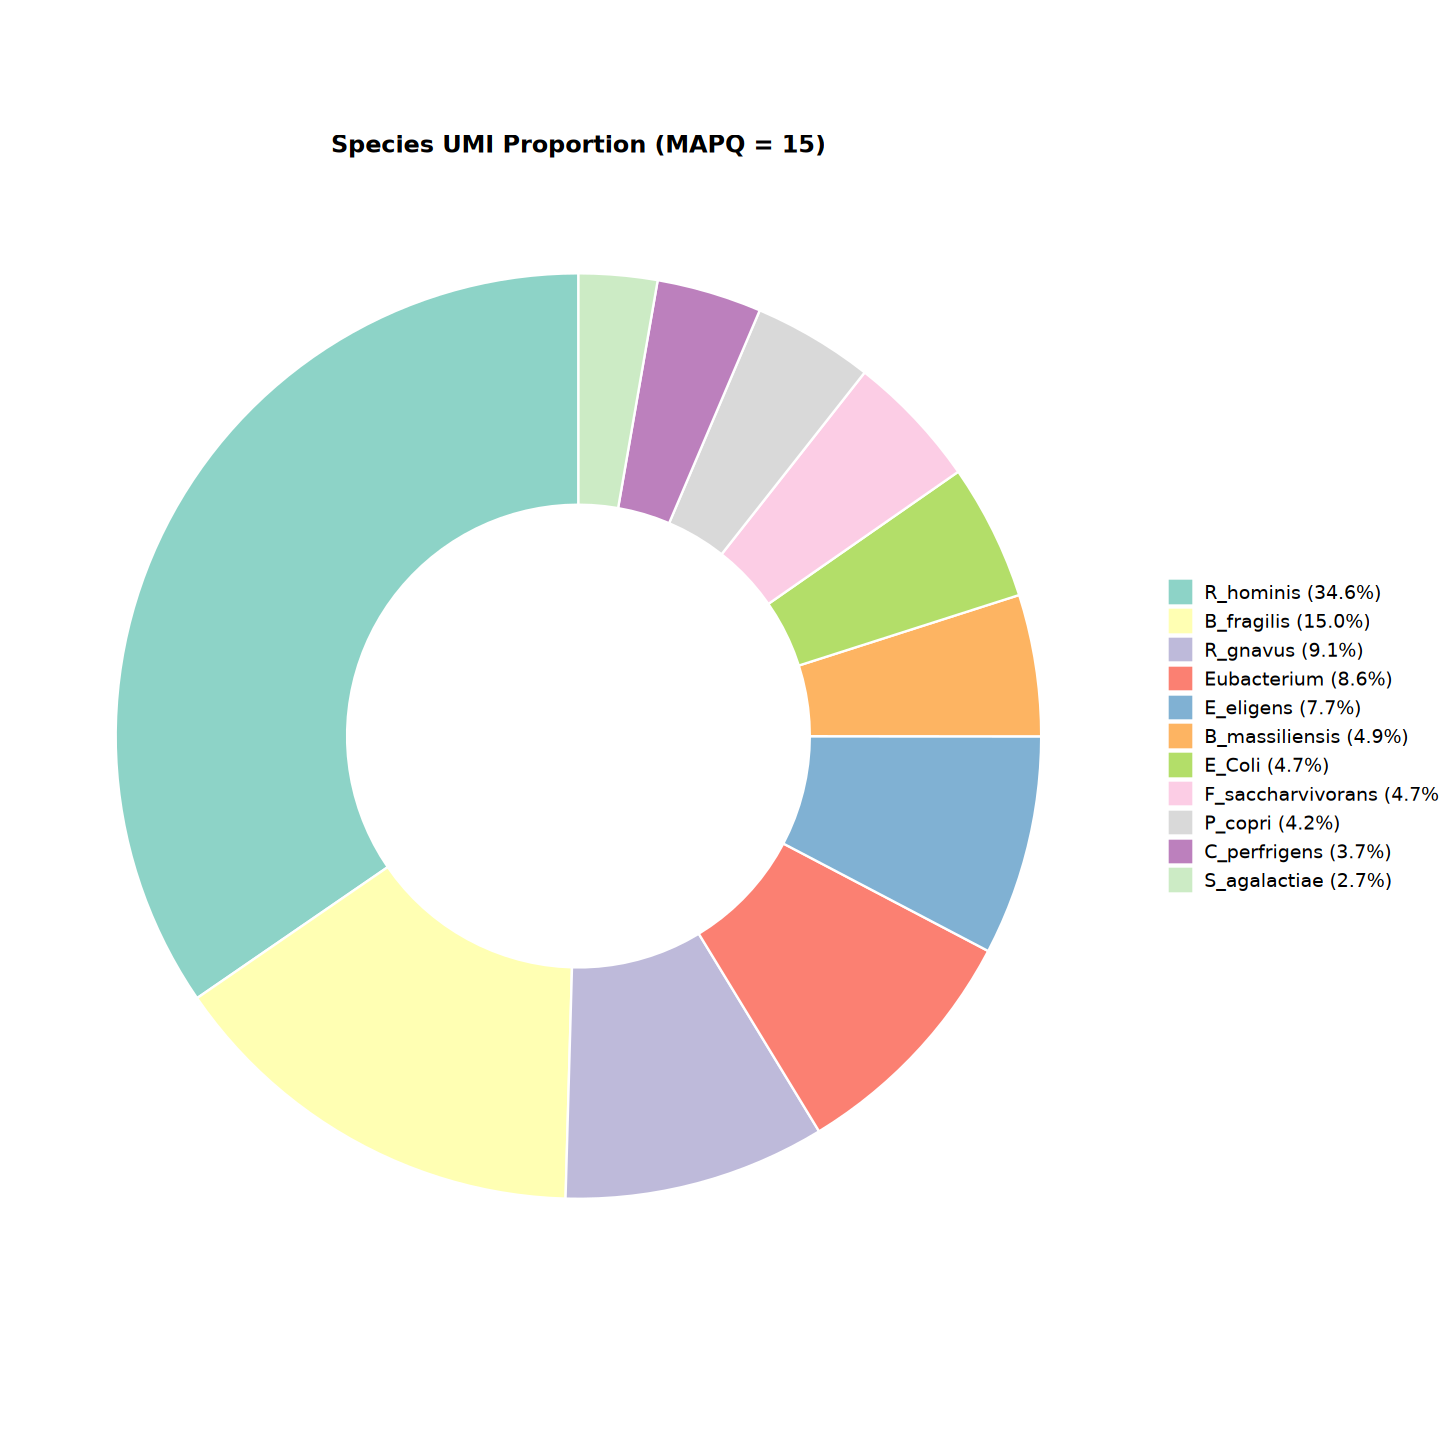

In [29]:
options(repr.plot.width=12,repr.plot.height=12)
p_donut

### H&E staining and spatial visualization of distance categories, total GUS-derived UMI counts, and speciesspecific GUS gene expression

In [30]:
SpatialMetaDataPlot_HostMicro <- function(host.rds,
                                         micro.rds,
                                         meta.col = "nCount_Spatial", # Metadata column to plot (replaces the former species argument)
                                         x.col = "imagecol",
                                         y.col = "imagerow",
                                         pt.size.host = 1.6,
                                         pt.size.micro = 1.5, # 0.8
                                         color.palette = viridis::viridis(11, option = "viridis"),
                                         background.color = "gray30",
                                         color.min = NULL,
                                         color.max = NULL,
                                         title = NULL,
                                         order = TRUE,
                                         verbose = TRUE,
                                         window.size = NULL,          # Side length of the plotting window (in coordinate units); NULL = fit to data
                                         scale.bar.length = 1000) {   # Length of the scale bar (in coordinate units, e.g., 1000 um)
  library(ggplot2)
  library(dplyr)
  library(viridis)

  # ---- 1. Host coordinates ----
  # Use the x.col and y.col arguments to extract coordinates
  host.coords <- GetTissueCoordinates(host.rds)
  host.coor <- host.rds@meta.data %>%
    mutate(x = host.coords[[x.col]],
           y = host.coords[[y.col]],
           expr = NA,
           orig = "Host")

  # ---- 2. Microbe coordinates and metadata extraction ----
  if (is.null(micro.rds)) stop("micro.rds cannot be NULL")
  
  # Check that the metadata column exists
  if (!(meta.col %in% colnames(micro.rds@meta.data))) {
    stop(paste0("Metadata column '", meta.col, "' not found in micro.rds"))
  }
  
  if (verbose) message("Plotting metadata column: ", meta.col)

  micro.coords <- GetTissueCoordinates(micro.rds)
  micro.meta <- micro.rds@meta.data %>%
    mutate(x = micro.coords[[x.col]],
           y = micro.coords[[y.col]],
           expr = .data[[meta.col]],  # Take the specified column directly from the metadata
           orig = "Microbes")

  # ---- 3. Merge ----
  merged <- bind_rows(
    host.coor %>% select(x, y, expr, orig),
    micro.meta %>% select(x, y, expr, orig)
  )

  # ---- 4. Determine the color range automatically (numeric data only) ----
  is_numeric <- is.numeric(merged$expr) # Check whether the data are continuous
  
  if (is_numeric) {
    expr_values <- merged$expr[!is.na(merged$expr)]
    if (is.null(color.min)) color.min <- min(expr_values, na.rm = TRUE)
    if (is.null(color.max)) color.max <- max(expr_values, na.rm = TRUE)
  } else {
    if (verbose) message("Note: ", meta.col, " is not numeric. Using discrete color scale.")
  }

  # ---- 5. Optional ordering (draw high values on top) ----
  if (order && is_numeric) {
    merged <- merged %>%
      arrange(expr)
  }

  # ---- Coordinate range and scale bar calculation (square plotting window enforced) ----
  # Obtain the actual extremes of the data
  data_max_x <- max(merged$x, na.rm = TRUE)
  data_min_x <- min(merged$x, na.rm = TRUE)
  data_max_y <- max(merged$y, na.rm = TRUE)
  data_min_y <- min(merged$y, na.rm = TRUE)
  
  x_range <- data_max_x - data_min_x
  y_range <- data_max_y - data_min_y

  if (!is.null(window.size)) {
    # Use a user-defined window size
    center_x <- (data_max_x + data_min_x) / 2
    center_y <- (data_max_y + data_min_y) / 2
    plot_max_x <- center_x + window.size / 2
    plot_min_x <- center_x - window.size / 2
    plot_max_y <- center_y + window.size / 2
    plot_min_y <- center_y - window.size / 2
  } else {
    # Compact mode: build square limits from the longer side to avoid extra margins caused by coord_fixed
    max_range <- max(x_range, y_range)
    pad_ratio <- 0.02 
    padded_range <- max_range * (1 + 2 * pad_ratio)
    
    center_x <- (data_max_x + data_min_x) / 2
    center_y <- (data_max_y + data_min_y) / 2
    
    plot_max_x <- center_x + padded_range / 2
    plot_min_x <- center_x - padded_range / 2
    plot_max_y <- center_y + padded_range / 2
    plot_min_y <- center_y - padded_range / 2
  }

  # Compute scale bar coordinates, anchored at the lower right of the square frame
  pad_x <- (plot_max_x - plot_min_x) * 0.03
  pad_y <- (plot_max_y - plot_min_y) * 0.03
  
  bar_xend <- plot_max_x - pad_x
  bar_x <- bar_xend - scale.bar.length
  bar_y <- plot_max_y - pad_y  

  # ---- 6. Plotting ----
  p <- ggplot(merged, aes(x = x, y = y)) +
    # Host (background, gray circles)
    geom_point(
      data = merged %>% filter(is.na(expr)),
      aes(shape = orig, size = orig),
      color = background.color
    ) +
    # Microbes (foreground, squares colored by the metadata value)
    geom_point(
      data = merged %>% filter(!is.na(expr)),
      aes(color = expr, shape = orig, size = orig)
    ) +
    # Draw the scale bar
    annotate("segment", x = bar_x, xend = bar_xend, y = bar_y, yend = bar_y, 
             color = "gray30", linewidth = 1.5) +  
    theme_void() +
    scale_shape_manual(values = c(`Host` = 16, `Microbes` = 15)) +
    scale_size_manual(values = c(`Host` = pt.size.host, `Microbes` = pt.size.micro))

  # ---- 7. Legend and color bar ----
  # Numeric data (e.g., nCount_Spatial): use a continuous color gradient
  if (is_numeric) {
    p <- p + scale_color_gradientn(
      colors = color.palette,
      name = meta.col,
      limits = c(color.min, color.max),
      oob = scales::squish
    ) +
    guides(
      shape = guide_legend(
        title = "Organism",
        override.aes = list(color = "white", size = 2.5),
        title.theme = element_text(size = 16),
        label.theme = element_text(size = 16),
        order = 1
      ),
      color = guide_colorbar(
        title = meta.col,
        title.theme = element_text(size = 16),
        label.theme = element_text(size = 16),
        barwidth = 12,
        barheight = 1,
        order = 2
      ),
      size = "none"
    )
  } else {
    # Discrete data (e.g., seurat_clusters): use a categorical legend
    p <- p + guides(
      shape = guide_legend(title = "Organism", order = 1),
      color = guide_legend(title = meta.col, order = 2),
      size = "none"
    )
  }

  # ---- 8. Theme and finishing ----
  plot_title <- if(!is.null(title)) title else meta.col

  p <- p + 
    # ggtitle(plot_title) +
    # Set the axis limits to keep the physical aspect ratio and reverse the y-axis
    scale_x_continuous(limits = c(plot_min_x, plot_max_x), expand = c(0, 0)) +
    scale_y_reverse(limits = c(plot_max_y, plot_min_y), expand = c(0, 0)) +
    coord_fixed(ratio = 1) +  
    theme(
      plot.title = element_text(size = 16),
      legend.position = "top",
      legend.direction = "horizontal",
      legend.box = "horizontal",
      legend.title = element_text(size = 16, hjust = 1, vjust = 1),
      legend.text = element_text(size = 16, hjust = 0.5, vjust = 0.5),
      legend.justification = "center"
    ) +
    SpatialTheme()
    
  return(p)
}

In [31]:
options(repr.plot.width = 15, repr.plot.height = 15)
p_p <- SpatialMetaDataPlot_HostMicro(host.rds = host.list$FMT_P,order = T,pt.size.micro = 1.5,
                              micro.rds = micro.list.updated$FMT_P,
                              meta.col = "GUS_Total_UMI",
                              color.min = 0,
                              color.max = 4,
                              )
p_m <- SpatialMetaDataPlot_HostMicro(host.rds = host.list$FMT_M,order = T,pt.size.micro = 1.5,
                              micro.rds = micro.list.updated$FMT_M,
                              meta.col = "GUS_Total_UMI",
                              color.min = 0,
                              color.max = 4,
                              )
p_d <- SpatialMetaDataPlot_HostMicro(host.rds = host.list$FMT_D,order = T,pt.size.micro = 1.5,
                              micro.rds = micro.list.updated$FMT_D,
                              meta.col = "GUS_Total_UMI",
                              color.min = 0,
                              color.max = 4,
                              )

ggsave(paste0("MAPQ",mapq,"_GUS_Signal.P.png"),p_p + NoLegend(), dpi = 300, width = 7,height = 7)
ggsave(paste0("MAPQ",mapq,"_GUS_Signal.M.png"),p_m + NoLegend(), dpi = 300, width = 7,height = 7)
ggsave(paste0("MAPQ",mapq,"_GUS_Signal.D.png"),p_d + NoLegend(), dpi = 300, width = 7,height = 7)
ggsave(paste0("MAPQ",mapq,"_GUS_Signal.Legend.pdf"),p_d + RestoreLegend(), dpi = 300, width = 7,height = 7)

Plotting metadata column: GUS_Total_UMI

Plotting metadata column: GUS_Total_UMI

Plotting metadata column: GUS_Total_UMI



In [32]:
species_vector <- c(
  "Escherichia-coli",           # E_Coli_Loop1_GUS
  "Clostridium-perfringens",    # C_perfrigens_Loop1_GUS
  "Mediterraneibacter-gnavus",  # R_gnavus_FMN_GUS
  "Lachnospira-rogosae",        # Eubacterium_FMN_GUS_(Lacnospira_Rogosae)
  "Streptococcus-agalactiae",   # S_agalactiae_Loop1_GUS
  "Lachnospira-eligens",        # E_eligens_Loop1_GUS
  "Bacteroides-fragilis",       # B_fragilis_miniLoop1_GUS
  "Fusicatenibacter-saccharivorans", # F_saccharvivorans_hybrid_GUS
  "Phocaeicola-massiliensis",        # B_massiliensis_miniLoop1_GUS
  "Segatella-copri",                 # P_copri_Loop2_GUS
  "Roseburia-hominis"                # R_hominis_1_miniLoop1_GUS
)

In [34]:
concern.taxon <- intersect(species_vector,Features(micro.list$FMT_P))

In [35]:
concern.taxon

[1] "Escherichia-coli"          "Clostridium-perfringens"  
[3] "Mediterraneibacter-gnavus" "Streptococcus-agalactiae" 
[5] "Lachnospira-eligens"       "Bacteroides-fragilis"     
[7] "Segatella-copri"           "Roseburia-hominis"

In [36]:
head(df)
# head(df_long)
# head(df_bin10)
# head(df_bin10_wide)

,CellID,Cx,Cy,B_fragilis,B_massiliensis,C_perfrigens,E_Coli,E_eligens,Eubacterium,F_saccharvivorans,P_copri,R_gnavus,R_hominis,S_agalactiae
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,00000CC88125,13756,15875,0,0,0,0,0,0,0,0,0,1,0
2,0001F1F46671,15120,10525,1,0,0,0,0,0,0,0,0,0,0
3,0008C0917F7F,7598,10267,2,0,0,0,0,0,0,0,0,0,0
4,000C050E01C8,14635,17132,1,0,0,0,0,0,0,0,0,0,0
5,000ECFD301C5,14592,6971,0,0,0,0,0,0,0,0,2,0,0
6,00100857091C,9333,9346,0,0,0,0,0,0,1,0,0,0,0


In [37]:
SpatialMetaDataPlot_HostMicro <- function(host.rds,
                                         micro.rds,
                                         meta.col = "nCount_Spatial", 
                                         x.col = "imagecol",
                                         y.col = "imagerow",
                                         pt.size.host = 1.6,
                                         pt.size.micro = 1.5, 
                                         pt.size.micro.expressed = 2.0, # Point size for microbial spots with expression (> 0)
                                         color.palette = viridis::viridis(11, option = "viridis"),
                                         background.color = "gray30",
                                         color.min = NULL,
                                         color.max = NULL,
                                         title = NULL,
                                         order = TRUE,
                                         verbose = TRUE,
                                         window.size = NULL,          
                                         scale.bar.length = 1000) {   
  library(ggplot2)
  library(dplyr)
  library(viridis)

  # ---- 1. Host coordinates ----
  host.coords <- GetTissueCoordinates(host.rds)
  host.coor <- host.rds@meta.data %>%
    mutate(x = host.coords[[x.col]],
           y = host.coords[[y.col]],
           expr = NA,
           orig = "Host")

  # ---- 2. Microbe coordinates and metadata extraction ----
  if (is.null(micro.rds)) stop("micro.rds cannot be NULL")
  
  if (!(meta.col %in% colnames(micro.rds@meta.data))) {
    stop(paste0("Metadata column '", meta.col, "' not found in micro.rds"))
  }
  
  if (verbose) message("Plotting metadata column: ", meta.col)

  micro.coords <- GetTissueCoordinates(micro.rds)
  micro.meta <- micro.rds@meta.data %>%
    mutate(x = micro.coords[[x.col]],
           y = micro.coords[[y.col]],
           expr = .data[[meta.col]],  
           orig = "Microbes")

  # ---- 3. Merge ----
  merged <- bind_rows(
    host.coor %>% select(x, y, expr, orig),
    micro.meta %>% select(x, y, expr, orig)
  )

  # ---- 4. Determine the color range automatically (numeric data only) ----
  is_numeric <- is.numeric(merged$expr) 
  
  if (is_numeric) {
    expr_values <- merged$expr[!is.na(merged$expr)]
    if (is.null(color.min)) color.min <- min(expr_values, na.rm = TRUE)
    if (is.null(color.max)) color.max <- max(expr_values, na.rm = TRUE)
    
    # Assign point-size groups (numeric data only): microbial spots are split by whether expr > 0
    merged <- merged %>%
      mutate(
        size_group = case_when(
          orig == "Host" ~ "Host",
          orig == "Microbes" & expr > 0 ~ "Microbes_Expressed",   # Values > 0 are labeled as expressed
          TRUE ~ "Microbes_Unexpressed"                           # Values equal to 0 or NA are labeled as not expressed
        )
      )
  } else {
    if (verbose) message("Note: ", meta.col, " is not numeric. Using discrete color scale.")
    # No size distinction for discrete data; fall back to the original category
    merged <- merged %>% mutate(size_group = orig)
  }

  # ---- 5. Optional ordering (draw high values on top) ----
  if (order && is_numeric) {
    merged <- merged %>%
      arrange(expr)
  }

  # ---- Coordinate range and scale bar calculation (square plotting window enforced) ----
  data_max_x <- max(merged$x, na.rm = TRUE)
  data_min_x <- min(merged$x, na.rm = TRUE)
  data_max_y <- max(merged$y, na.rm = TRUE)
  data_min_y <- min(merged$y, na.rm = TRUE)
  
  x_range <- data_max_x - data_min_x
  y_range <- data_max_y - data_min_y

  if (!is.null(window.size)) {
    center_x <- (data_max_x + data_min_x) / 2
    center_y <- (data_max_y + data_min_y) / 2
    plot_max_x <- center_x + window.size / 2
    plot_min_x <- center_x - window.size / 2
    plot_max_y <- center_y + window.size / 2
    plot_min_y <- center_y - window.size / 2
  } else {
    max_range <- max(x_range, y_range)
    pad_ratio <- 0.02 
    padded_range <- max_range * (1 + 2 * pad_ratio)
    
    center_x <- (data_max_x + data_min_x) / 2
    center_y <- (data_max_y + data_min_y) / 2
    
    plot_max_x <- center_x + padded_range / 2
    plot_min_x <- center_x - padded_range / 2
    plot_max_y <- center_y + padded_range / 2
    plot_min_y <- center_y - padded_range / 2
  }

  pad_x <- (plot_max_x - plot_min_x) * 0.03
  pad_y <- (plot_max_y - plot_min_y) * 0.03
  
  bar_xend <- plot_max_x - pad_x
  bar_x <- bar_xend - scale.bar.length
  bar_y <- plot_max_y - pad_y  

  # ---- 6. Plotting ----
  p <- ggplot(merged, aes(x = x, y = y)) +
    # Host (background, gray circles)
    geom_point(
      data = merged %>% filter(is.na(expr)),
      aes(shape = orig, size = size_group), # Point size is mapped to size_group
      color = background.color
    ) +
    # Microbes (foreground, squares colored by the metadata value)
    geom_point(
      data = merged %>% filter(!is.na(expr)),
      aes(color = expr, shape = orig, size = size_group) # Point size is mapped to size_group
    ) +
    annotate("segment", x = bar_x, xend = bar_xend, y = bar_y, yend = bar_y, 
             color = "gray30", linewidth = 1.5) +  
    theme_void() +
    scale_shape_manual(values = c(`Host` = 16, `Microbes` = 15)) +
    # Point sizes for each size group
    scale_size_manual(values = c(
      `Host` = pt.size.host, 
      `Microbes` = pt.size.micro,                      # Fallback for discrete data
      `Microbes_Unexpressed` = pt.size.micro,          # Unexpressed spots keep the smaller size
      `Microbes_Expressed` = pt.size.micro.expressed   # Expressed spots are enlarged
    ))

  # ---- 7. Legend and color bar ----
  if (is_numeric) {
    p <- p + scale_color_gradientn(
      colors = color.palette,
      name = meta.col,
      limits = c(color.min, color.max),
      oob = scales::squish
    ) +
    guides(
      shape = guide_legend(
        title = "Organism",
        override.aes = list(color = "white", size = 2.5),
        title.theme = element_text(size = 16),
        label.theme = element_text(size = 16),
        order = 1
      ),
      color = guide_colorbar(
        title = meta.col,
        title.theme = element_text(size = 16),
        label.theme = element_text(size = 16),
        barwidth = 12,
        barheight = 1,
        order = 2
      ),
      size = "none" # Hide the size legend to keep the figure uncluttered
    )
  } else {
    p <- p + guides(
      shape = guide_legend(title = "Organism", order = 1),
      color = guide_legend(title = meta.col, order = 2),
      size = "none"
    )
  }

  # ---- 8. Theme and finishing ----
  plot_title <- if(!is.null(title)) title else meta.col

  p <- p + 
    scale_x_continuous(limits = c(plot_min_x, plot_max_x), expand = c(0, 0)) +
    scale_y_reverse(limits = c(plot_max_y, plot_min_y), expand = c(0, 0)) +
    coord_fixed(ratio = 1) +  
    theme(
      plot.title = element_text(size = 16),
      legend.position = "top",
      legend.direction = "horizontal",
      legend.box = "horizontal",
      legend.title = element_text(size = 16, hjust = 1, vjust = 1),
      legend.text = element_text(size = 16, hjust = 0.5, vjust = 0.5),
      legend.justification = "center"
    ) +
    SpatialTheme()
    
  return(p)
}

In [38]:
# Load required packages
library(tidyverse)
library(patchwork)

main_sub_dir <- "MicroExpr_SpeciesIndepedent/"
if (!dir.exists(main_sub_dir)) {
  dir.create(main_sub_dir)
}

# -------------------------------------------------------------------
# 1. Data import and basic cleaning
# -------------------------------------------------------------------
mapq <- 15

df <- read.csv(paste0("/home/han_xiao/xiaohan/Others/Sunny/03.result/04-Spatial_GUS/03.DNA_bwaAdj/Spatial_GUS_MAPQ", mapq, ".csv"))

# Batch-rename the columns of df
df <- df %>%
  rename_with(
    # Regular expression: remove the suffix that starts with an underscore followed by (1_)?, miniLoop, Loop, FMN or hybrid, together with everything after it
    ~ str_remove(., "_(1_)?(miniLoop|Loop|FMN|hybrid).*$"), 
    # Exclude the columns that should not be renamed (the first three columns)
    cols = -c(CellID, Cx, Cy) 
  )

# Map the column names to the 11 full taxonomic names
df <- df %>%
  rename(
    "Bacteroides-fragilis" = B_fragilis,
    "Clostridium-perfringens" = C_perfrigens, 
    "Escherichia-coli" = E_Coli,
    "Fusicatenibacter-saccharivorans" = F_saccharvivorans, # Corrects the spelling of saccharivorans
    "Lachnospira-eligens" = E_eligens,
    "Lachnospira-rogosae" = Eubacterium,
    "Mediterraneibacter-gnavus" = R_gnavus,
    "Phocaeicola-massiliensis" = B_massiliensis,
    "Roseburia-hominis" = R_hominis,
    "Segatella-copri" = P_copri,
    "Streptococcus-agalactiae" = S_agalactiae
  )

# df <- df %>% select(-`Fusicatenibacter-saccharivorans`,-`Lachnospira-rogosae`,-`Phocaeicola-massiliensis`)


# Reshape from wide to long format and clean the data
df_long <- df %>%
  pivot_longer(
    # Exclude CellID as well so it is not treated as a gene column
    cols = -c(CellID, Cx, Cy), 
    names_to = "Raw_Column",   
    values_to = "Expression"   
  ) %>%
  # Remove spots with zero expression to eliminate background noise and greatly reduce data size
  filter(Expression > 0) %>%
  mutate(
    # Extract GeneName
    GeneName = Raw_Column
  )

# -------------------------------------------------------------------
# 2. Spatial Bin10 downsampling and reshaping to wide format
# -------------------------------------------------------------------
df_bin10 <- df_long %>%
  mutate(
    # Spatial binning logic: 268 %/% 10 = 26, 26 * 10 = 260
    Cx_Bin10 = (Cx %/% 10) * 10,
    Cy_Bin10 = (Cy %/% 10) * 10
  ) %>%
  # Group by binned coordinates and gene name
  group_by(Cx_Bin10, Cy_Bin10, GeneName) %>%
  # Sum the UMI counts of the same gene within the same bin
  summarise(
    Expression = sum(Expression),
    .groups = "drop" # Ungroup immediately after summarising
  )

# Convert the long table to wide format so that each GeneName becomes its own column, and compute the total
df_bin10_wide <- df_bin10 %>%
  pivot_wider(
    names_from = GeneName,
    values_from = Expression,
    values_fill = 0 # Fill with 0 if the bin has no expression of that gene
  ) %>%
  # Row-wise sum of the total UMI count across all features (excluding the coordinate columns)
  mutate(
    GUS_Total_UMI = rowSums(select(., -Cx_Bin10, -Cy_Bin10))
  )

# Extract the names of all columns to be plotted (everything except the coordinates: GUS_Total_UMI and each individual feature)
feature_cols <- setdiff(colnames(df_bin10_wide), c("Cx_Bin10", "Cy_Bin10"))

# -------------------------------------------------------------------
# 3. Batch-update the metadata of the Seurat objects
# -------------------------------------------------------------------
# Copy the original list to protect the original micro.list from modification
micro.list.updated <- micro.list

for (segment in names(micro.list)) {
  message("Merging metadata: ", segment, " ...")
  
  current_micro <- micro.list.updated[[segment]]
  meta_data <- current_micro@meta.data
  
  meta_data_updated <- meta_data %>%
    left_join(
      df_bin10_wide,
      by = c("x" = "Cx_Bin10", "y" = "Cy_Bin10")
    ) %>%
    # Replace NA with 0 in all feature columns (background spots with no expression are set to 0)
    mutate(across(all_of(feature_cols), ~ replace_na(., 0)))
  
  # Restore row names and write the updated metadata back to current_micro
  rownames(meta_data_updated) <- rownames(meta_data)
  current_micro@meta.data <- meta_data_updated
  
  # Save the object with updated metadata back to the list
  micro.list.updated[[segment]] <- current_micro
}

message("Metadata merging completed. Starting batch plotting...")

# -------------------------------------------------------------------
# 4. Batch plotting and saving
# -------------------------------------------------------------------
options(repr.plot.width = 15, repr.plot.height = 15)

# Loop over every feature (the total and each individual feature)
for (feature in feature_cols) {
  message("Plotting and saving feature: ", feature, " ...")
  
  # ---------- Plot the P segment ----------
  p_p <- SpatialMetaDataPlot_HostMicro(pt.size.micro.expressed = 3,
    host.rds = host.list$FMT_P, 
    order = TRUE, pt.size.micro = 1.5,
    micro.rds = micro.list.updated$FMT_P,
    meta.col = feature,
    color.min = 0, color.max = 3
  )
  
  # ---------- Plot the M segment ----------
  p_m <- SpatialMetaDataPlot_HostMicro(pt.size.micro.expressed = 3,
    host.rds = host.list$FMT_M, 
    order = TRUE, pt.size.micro = 1.5,
    micro.rds = micro.list.updated$FMT_M,
    meta.col = feature,
    color.min = 0, color.max = 3
  )
  
  # ---------- Plot the D segment ----------
  p_d <- SpatialMetaDataPlot_HostMicro(pt.size.micro.expressed = 3,
    host.rds = host.list$FMT_D, 
    order = TRUE, pt.size.micro = 1.5,
    micro.rds = micro.list.updated$FMT_D,
    meta.col = feature,
    color.min = 0, color.max = 3
  )
  
  # ---------- Save the figures ----------
  # Dynamically generate the prefix, e.g., "MAPQ15_GUS_Total_UMI" or "MAPQ15_Escherichia-coli"
  prefix <- paste0("MAPQ", mapq, "_", feature)
  
  ggsave(paste0(main_sub_dir,prefix, "_Signal.P.png"), p_p + NoLegend(), dpi = 300, width = 7, height = 7,units = "in")
  ggsave(paste0(main_sub_dir,prefix, "_Signal.M.png"), p_m + NoLegend(), dpi = 300, width = 7, height = 7,units = "in")
  ggsave(paste0(main_sub_dir,prefix, "_Signal.D.png"), p_d + NoLegend(), dpi = 300, width = 7, height = 7,units = "in")
  # Use the legend of the D segment as the representative and save it as a separate PDF
  ggsave(paste0(main_sub_dir,"Signal.Legend.pdf"), p_d + RestoreLegend(), dpi = 300, width = 7, height = 7)
}

message("All tasks completed.")

正在合并 Metadata: FMT_P ...

正在合并 Metadata: FMT_M ...

正在合并 Metadata: FMT_D ...

Metadata 合并完毕！即将开始批量绘图...

正在绘制并保存特征: Bacteroides-fragilis ...

Plotting metadata column: Bacteroides-fragilis

Plotting metadata column: Bacteroides-fragilis

Plotting metadata column: Bacteroides-fragilis

正在绘制并保存特征: Phocaeicola-massiliensis ...

Plotting metadata column: Phocaeicola-massiliensis

Plotting metadata column: Phocaeicola-massiliensis

Plotting metadata column: Phocaeicola-massiliensis

正在绘制并保存特征: Lachnospira-eligens ...

Plotting metadata column: Lachnospira-eligens

Plotting metadata column: Lachnospira-eligens

Plotting metadata column: Lachnospira-eligens

正在绘制并保存特征: Clostridium-perfringens ...

Plotting metadata column: Clostridium-perfringens

Plotting metadata column: Clostridium-perfringens

Plotting metadata column: Clostridium-perfringens

正在绘制并保存特征: Streptococcus-agalactiae ...

Plotting metadata column: Streptococcus-agalactiae

Plotting metadata column: Streptococcus-agalactiae

Pl

In [39]:
library(ggplot2)

FMT_P <- micro.list$FMT_P
FMT_M <- micro.list$FMT_M
FMT_D <- micro.list$FMT_D

# ---------------------------------------------------------
# 1. Define distance intervals and create a new column
# ---------------------------------------------------------
categorize_distance <- function(dist) {
  group <- rep(NA_character_, length(dist))
  group[dist >= 0 & dist <= 150] <- "0-150"
  group[dist > 150] <- ">150"
  return(factor(group, levels = c("0-150", ">150")))
}

FMT_P$dist_group <- categorize_distance(FMT_P$min_dist)
FMT_M$dist_group <- categorize_distance(FMT_M$min_dist)
FMT_D$dist_group <- categorize_distance(FMT_D$min_dist)

# ---------------------------------------------------------
# 2. Define the discrete color palette
# ---------------------------------------------------------
cns_darkbg_colors <- c(
  "0-150" = "#efa9c2",   
  ">150" = "#7aa6dc"  
)

# ---------------------------------------------------------
# 3. Plotting
# ---------------------------------------------------------
# Draw with the underlying function first (it may emit warnings about the default color scale, which can be ignored)
p_p <- SpatialMetaDataPlot_HostMicro(host.rds = host.list$FMT_P, pt.size.host = 0.8, pt.size.micro = 0.6,
                                     order = T,
                                     micro.rds = FMT_P,
                                     meta.col = "dist_group")

p_m <- SpatialMetaDataPlot_HostMicro(host.rds = host.list$FMT_M, pt.size.host = 0.8, pt.size.micro = 0.6,
                                     order = T,
                                     micro.rds = FMT_M,
                                     meta.col = "dist_group")

p_d <- SpatialMetaDataPlot_HostMicro(host.rds = host.list$FMT_D, pt.size.host = 0.8, pt.size.micro = 0.6,
                                     order = T,
                                     micro.rds = FMT_D,
                                     meta.col = "dist_group")

# ---------------------------------------------------------
# 4. Apply the custom color scheme externally
# ---------------------------------------------------------
# na.value = "transparent" makes spots with NA values fully transparent.
# It can be changed to "black" or "grey20" depending on the background.

p_p <- p_p + 
  scale_color_manual(values = cns_darkbg_colors, na.value = "transparent") +
  scale_fill_manual(values = cns_darkbg_colors, na.value = "transparent")

p_m <- p_m + 
  scale_color_manual(values = cns_darkbg_colors, na.value = "transparent") +
  scale_fill_manual(values = cns_darkbg_colors, na.value = "transparent")

p_d <- p_d + 
  scale_color_manual(values = cns_darkbg_colors, na.value = "transparent") +
  scale_fill_manual(values = cns_darkbg_colors, na.value = "transparent")

# ---------------------------------------------------------
# 5. Export the figures
# ---------------------------------------------------------
library(ggplot2) # NoLegend() is provided by Seurat; see the note on dependencies

ggsave(paste0("Fig3D.DistanceCatagory.P.png"), p_p + NoLegend(), dpi = 300, width = 7, height = 7)
ggsave(paste0("Fig3D.DistanceCatagory.M.png"), p_m + NoLegend(), dpi = 300, width = 7, height = 7)
ggsave(paste0("Fig3D.DistanceCatagory.D.png"), p_d + NoLegend(), dpi = 300, width = 7, height = 7)
ggsave(paste0("Fig3D.DistanceCatagory.Legend.pdf"), p_d, dpi = 300, width = 7, height = 7)

Plotting metadata column: dist_group

Note: dist_group is not numeric. Using discrete color scale.

Plotting metadata column: dist_group

Note: dist_group is not numeric. Using discrete color scale.

Plotting metadata column: dist_group

Note: dist_group is not numeric. Using discrete color scale.

Warning message:
“No shared levels found between `names(values)` of the manual scale and the data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the data's fill values.”


Warning message:
“No shared levels found between `names(values)` of the manual scale and the data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the data's fill values.”


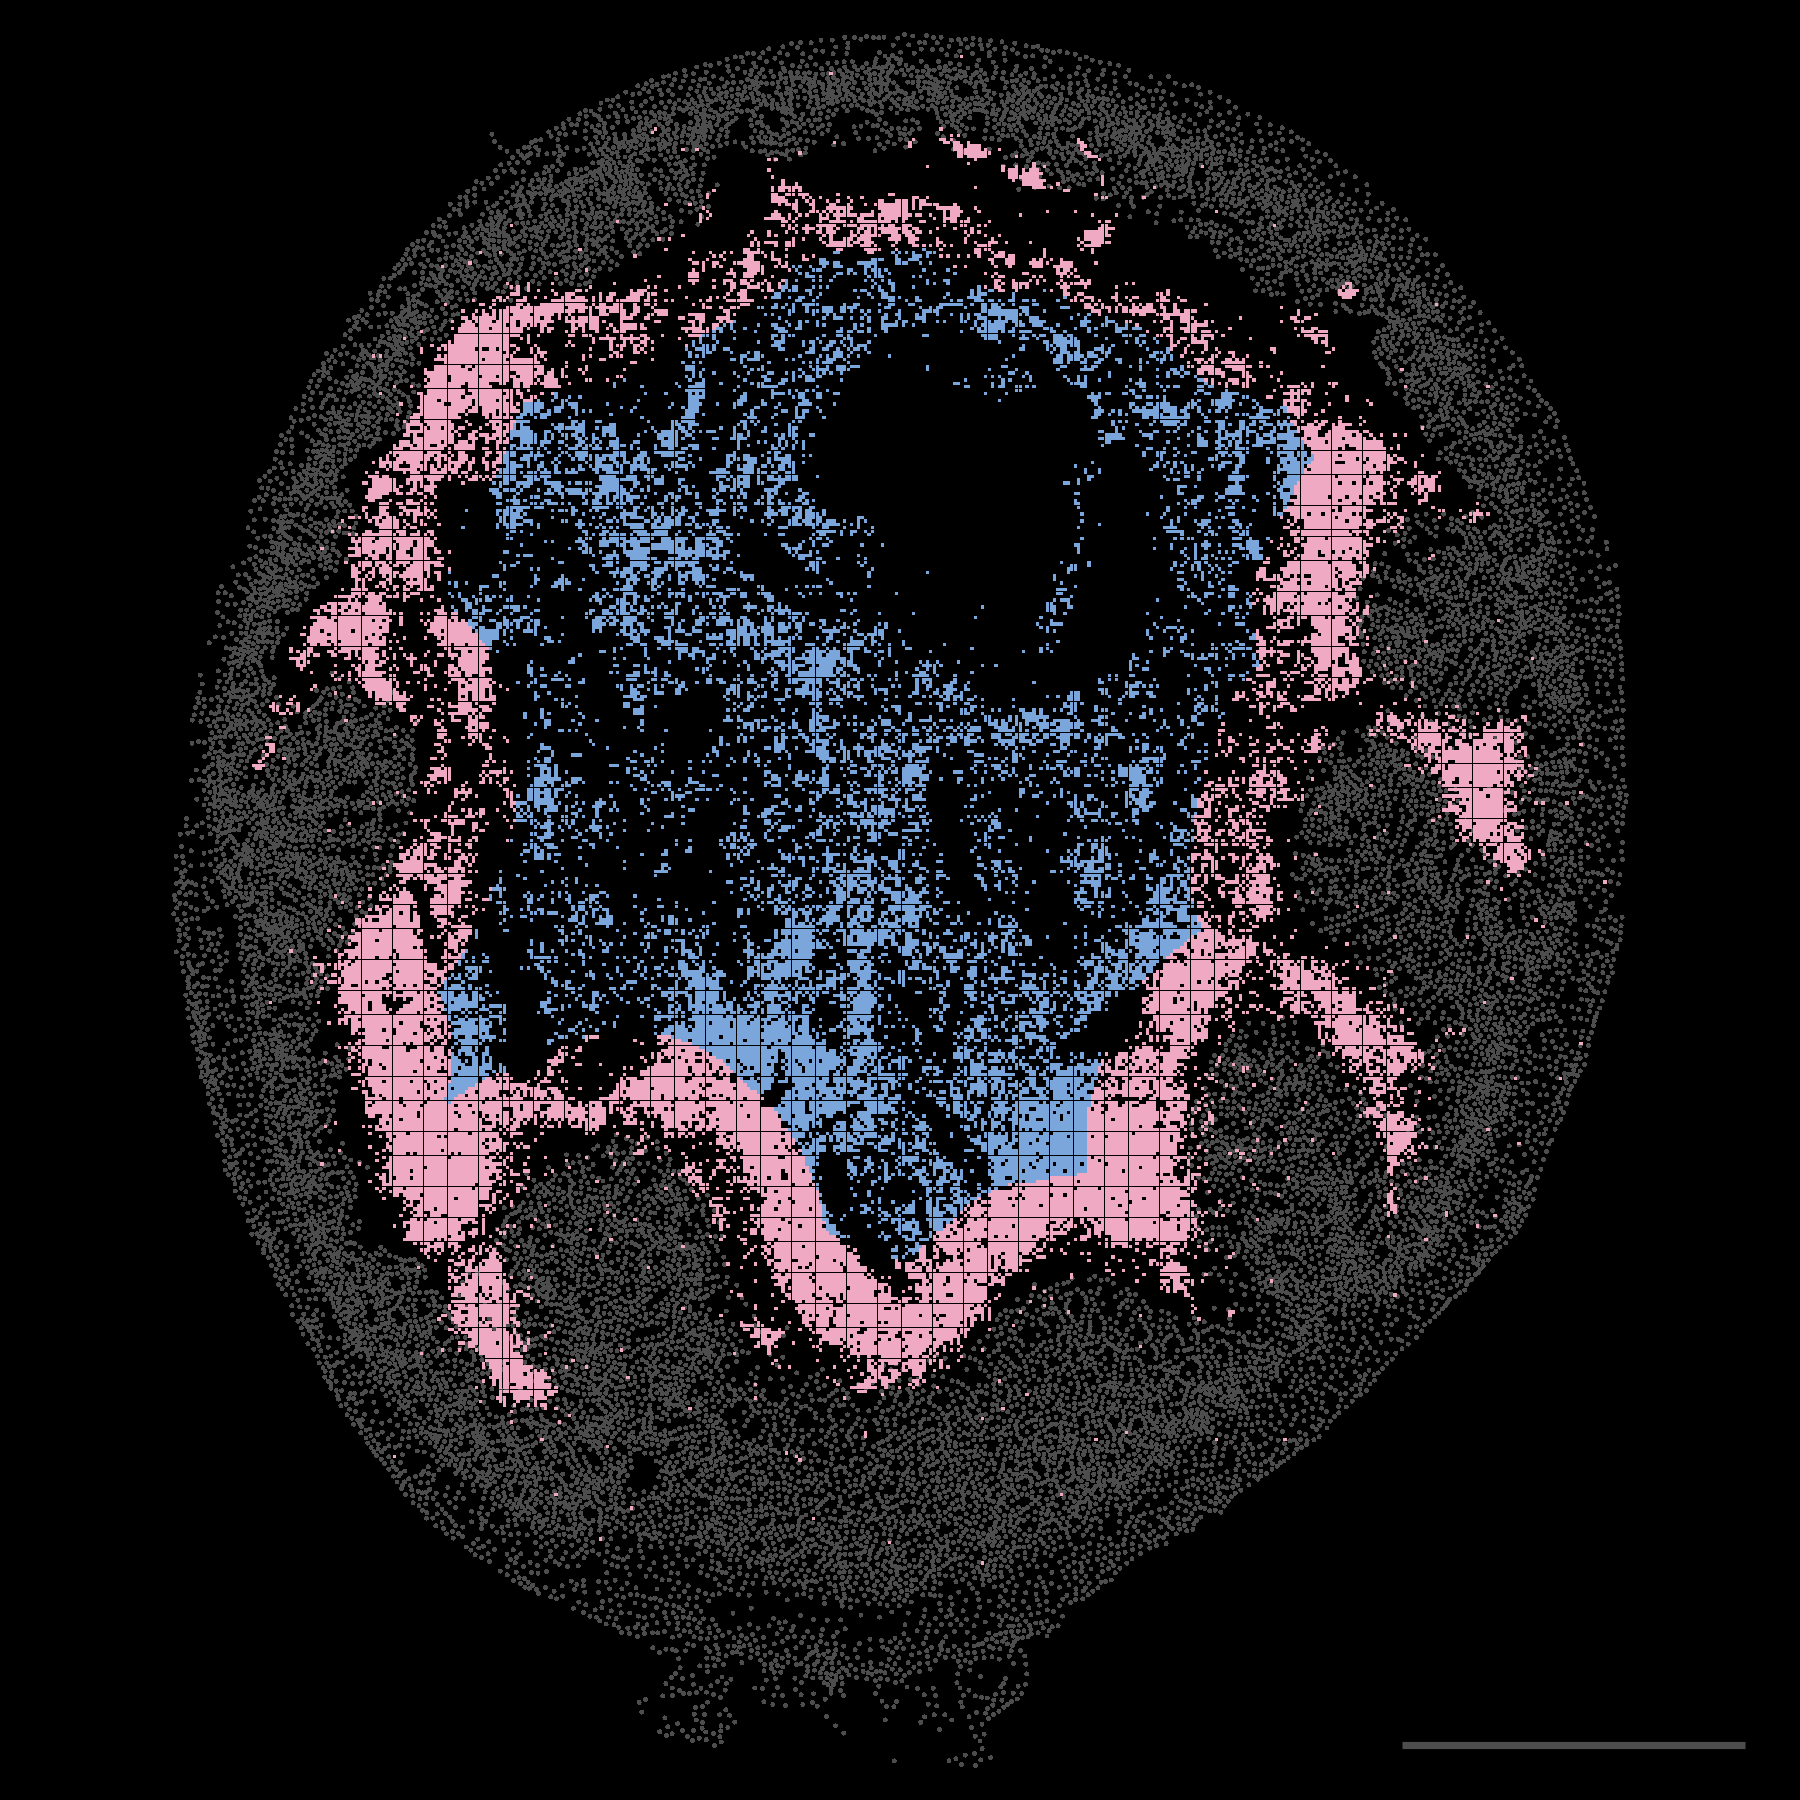

Warning message:
“No shared levels found between `names(values)` of the manual scale and the data's fill values.”


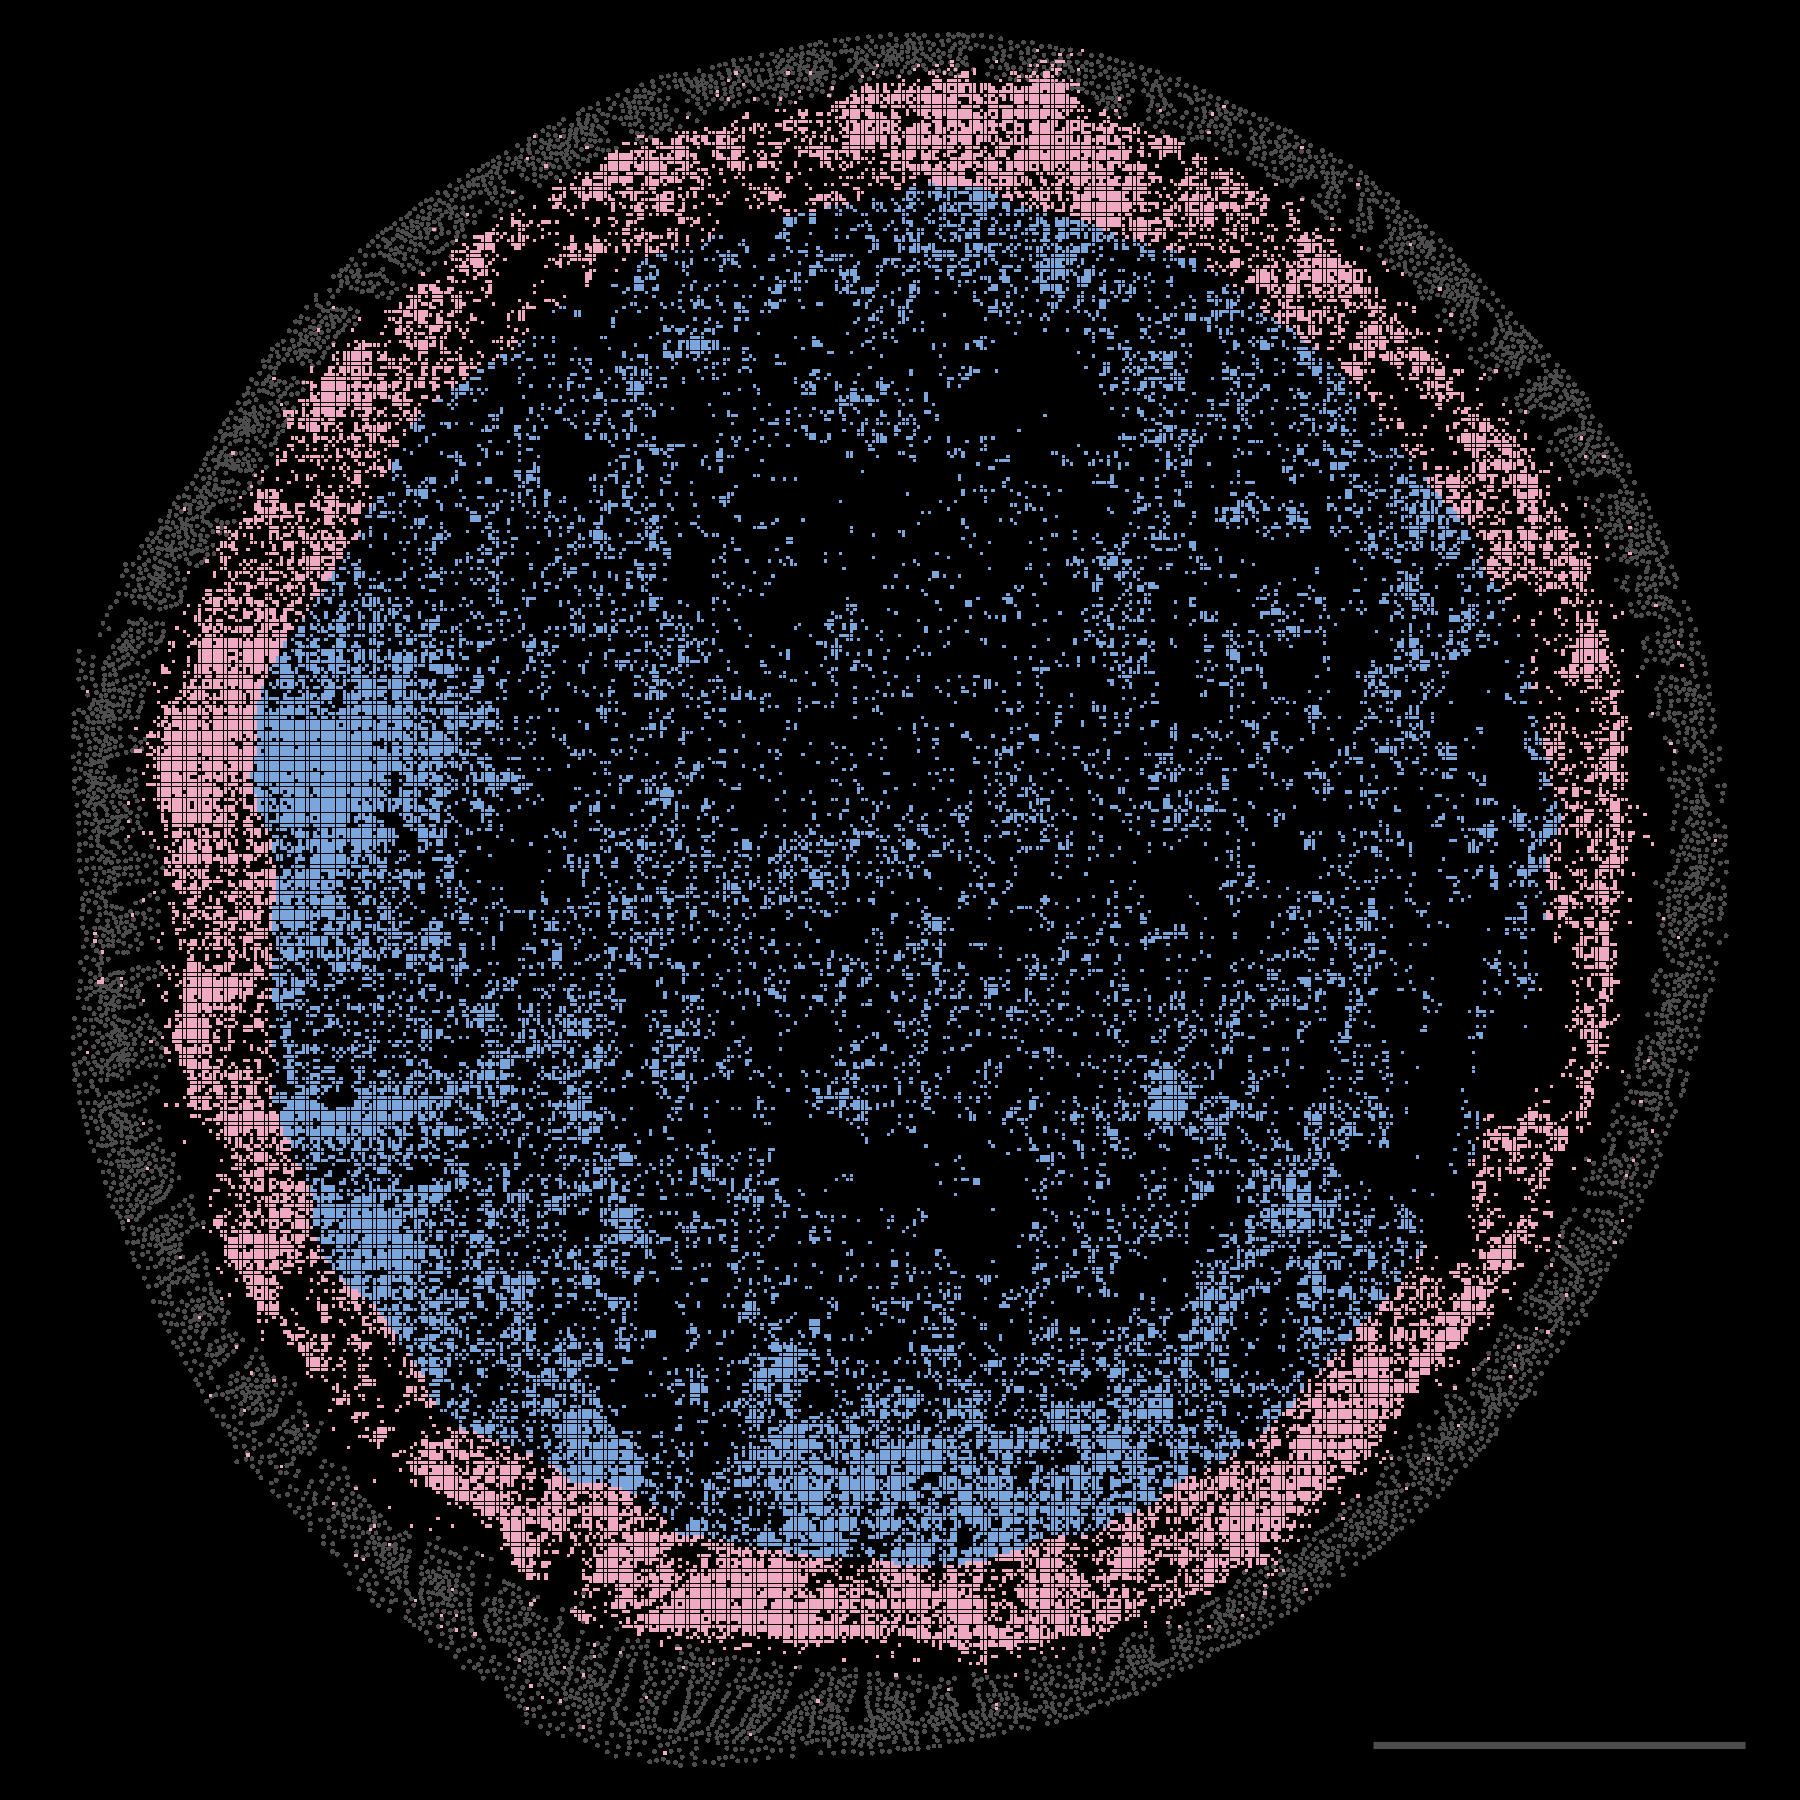

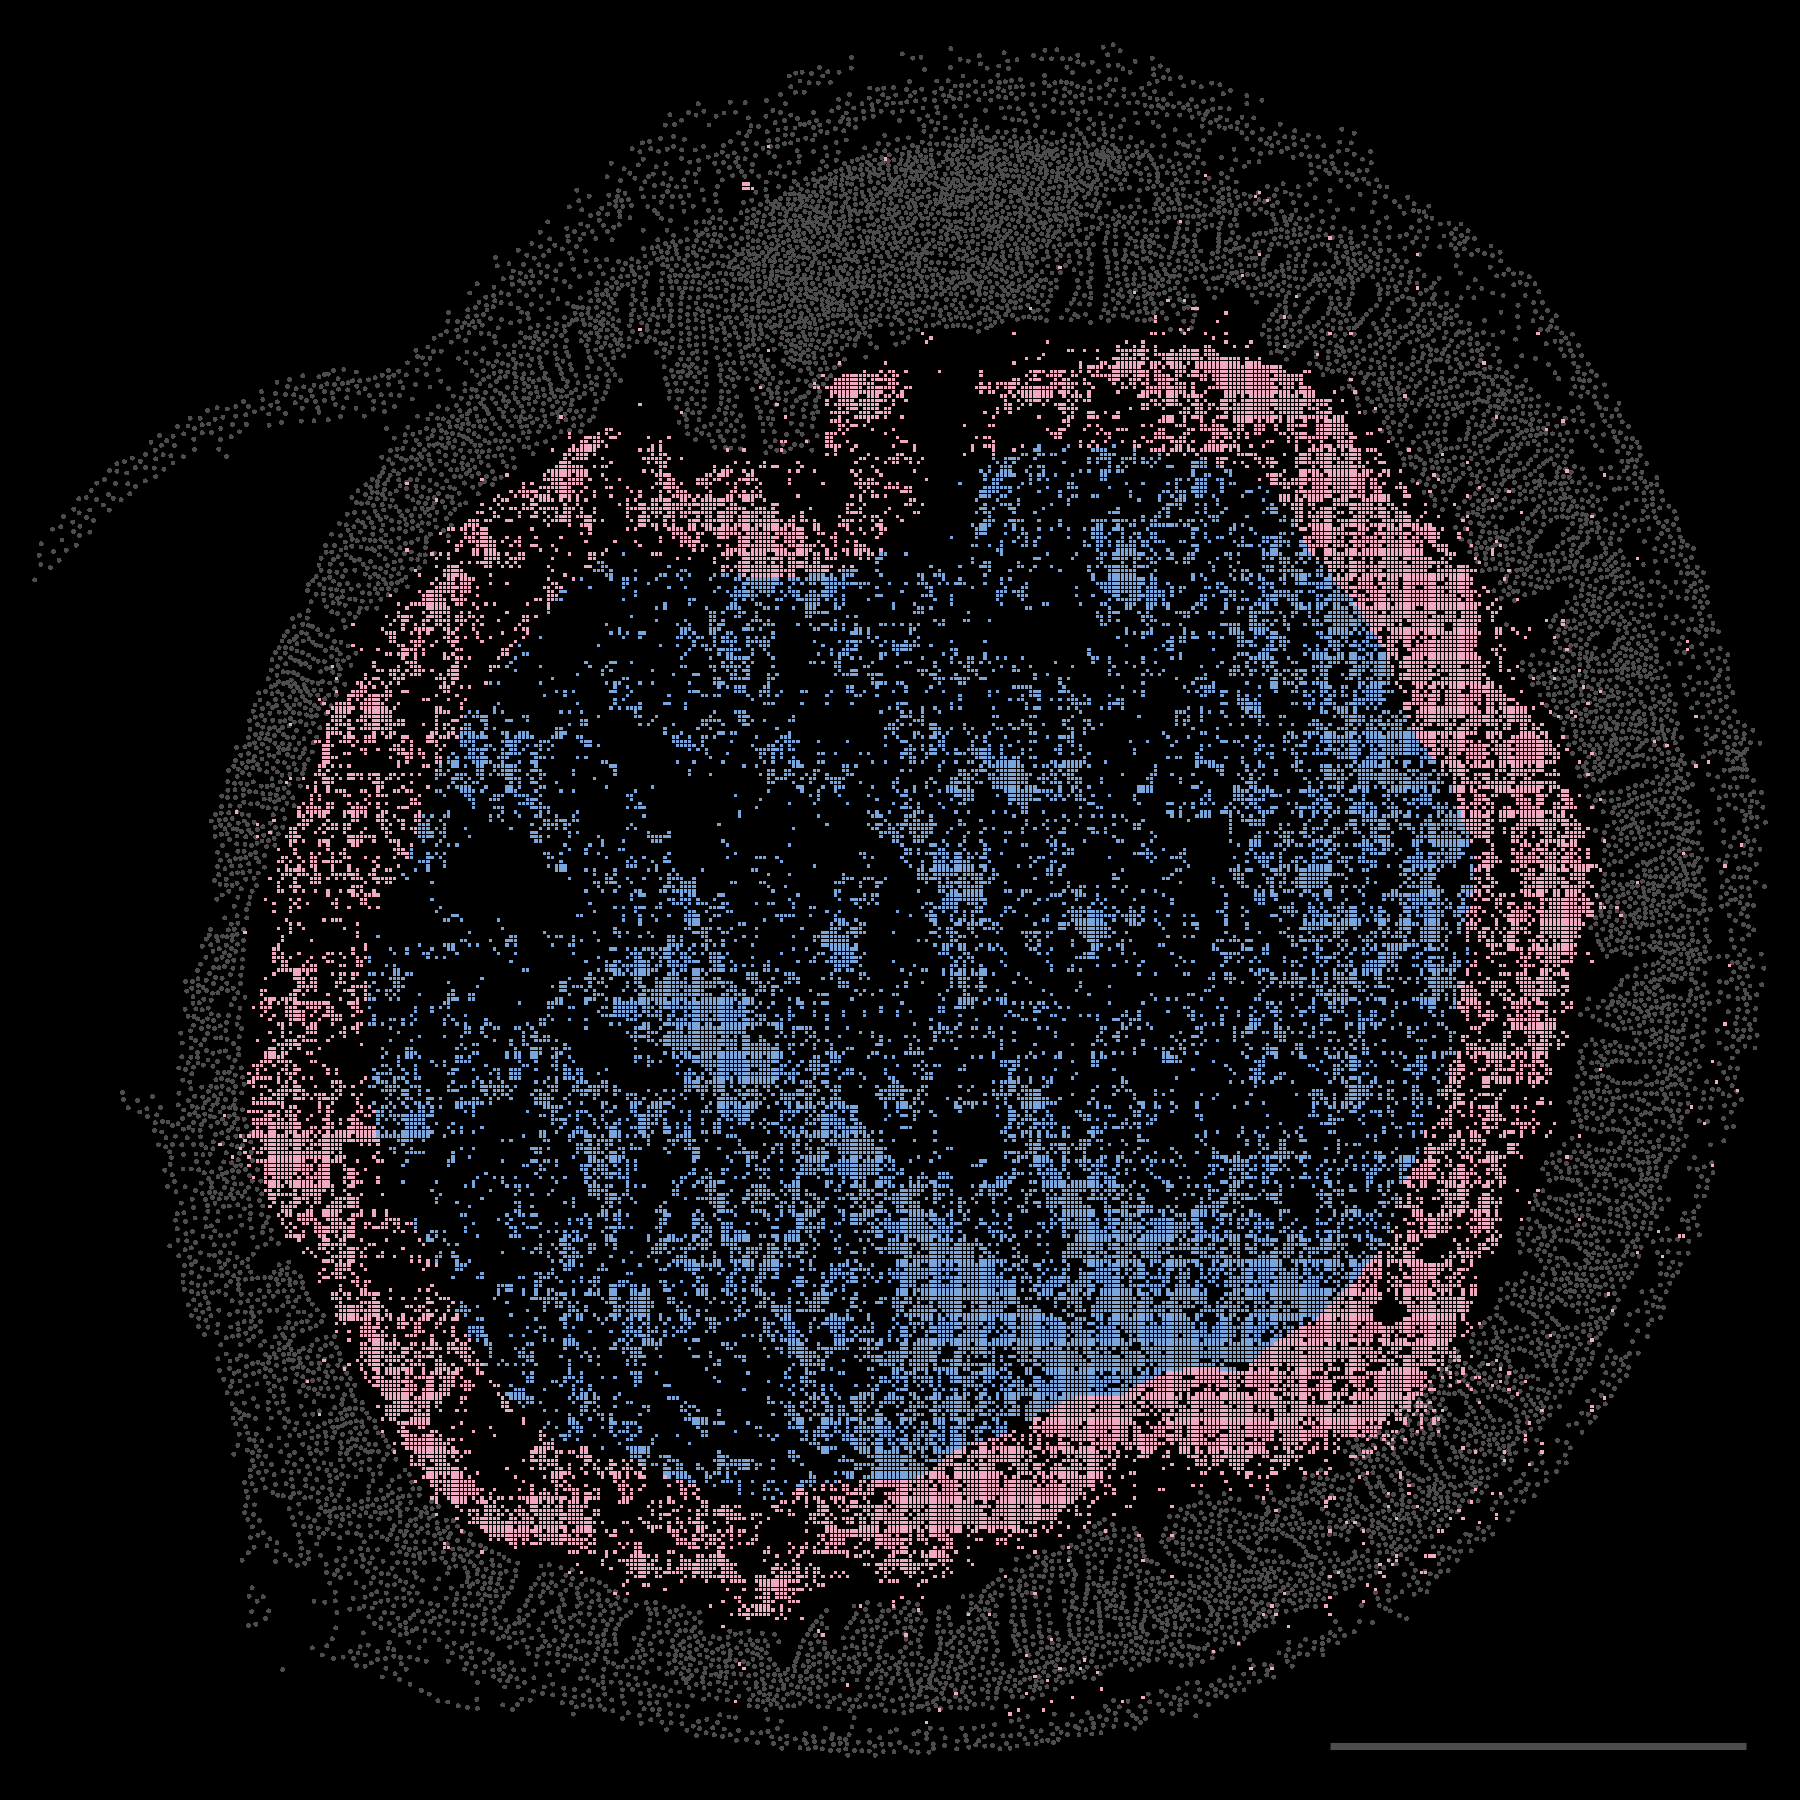

In [40]:
p_p
p_m
p_d